# Etapa 7. Similitud aproximada (MinHash + LSH y HNSW)

**Proyecto EDA 2026-2, Grupo 1, escenario B (comercio electrónico).**
Responsable de la etapa 7: Axel.

## Función de la etapa en el pipeline

El escenario B pide **generar productos similares y recomendaciones complementarias a partir de atributos y comportamiento de compra**. La etapa 7 responde "¿qué productos se parecen a este?" con dos familias de búsqueda aproximada, una por cada fuente que menciona el enunciado.

| Fuente | Representación del producto | Similitud | Estructura aproximada | Línea base exacta |
| --- | --- | --- | --- | --- |
| Comportamiento de compra | Conjunto de usuarios que interactuaron con el producto (matriz de la etapa 3) | Jaccard | **MinHash + LSH** (Broder, 1997; Indyk y Motwani, 1998) | Fuerza bruta: Jaccard con todos los productos |
| Atributos del producto | Vector de dimensión alta con el título, la categoría y la tienda (catálogo de la etapa 3) | Euclidiana entre vectores de norma 1, que ordena igual que el coseno | **HNSW** (Malkov y Yashunin, 2020) | KNN exacto con el KD-Tree y la fuerza bruta de la etapa 5 |

**Por qué MinHash + LSH y no SimHash.** El enunciado ofrece MinHash + LSH para Jaccard o SimHash para coseno y casi duplicados. La entrada por comportamiento es un conjunto sin pesos, el de los usuarios de cada producto, y la medida natural entre conjuntos es Jaccard. SimHash aproxima el coseno entre vectores con pesos y está pensado para detectar casi duplicados (Charikar, 2002).

**Por qué HNSW y no IVF ni un árbol métrico.** El espacio de los vectores es euclidiano, así que no hace falta un árbol métrico como el M-Tree o el VP-Tree, que sirven para cualquier métrica. HNSW es el método que cita el enunciado y no necesita entrenar centroides como IVF. El experimento B de la etapa 5 mostró además que desde d = 16 el KD-Tree evalúa prácticamente todos los puntos, así que en dimensión alta hace falta una búsqueda aproximada.

**Integración con las etapas anteriores.**

- **Etapa 3.** La transpuesta de su matriz usuario × producto da el conjunto de usuarios de cada producto, como anticipa el notebook de la etapa 3. Su catálogo en disco da el título, la categoría de último nivel y la tienda.
- **Etapa 5.** `knn_fuerza_bruta` es la referencia exacta del recall@K de HNSW, como anticipa el notebook de la etapa 5, y su `KDTree` es el KNN exacto con índice.
- **Etapa 6.** Los usuarios con alguna orden bloqueada se quitan de los conjuntos antes de calcular las firmas, para que el fraude no cree similitudes entre los productos que compró. El paso 2 mide su efecto.
- **Etapa 2.** El `MinHeap` guarda los candidatos y los resultados de la búsqueda de HNSW.

**Salidas para las etapas siguientes.** `relacionados.parquet` (los K productos de mayor Jaccard según MinHash + LSH) y `similares.parquet` (los K productos más cercanos según HNSW), en `data/interim/<CATEGORIA>/etapa_7/`, para las recomendaciones de la etapa 9.

## Proceso

```
matriz usuario × producto (etapa 3) − usuarios bloqueados (etapa 6)      catálogo (etapa 3)
   │                                                                      │
   ├─ 1. transponer: conjunto de usuarios de cada producto                ├─ 1. rasgos: palabras del título, categoría y tienda
   ├─ 2. firmas MinHash de n_hashes valores          O(nnz · n_hashes)    ├─ 2. TF-IDF con hashing trick y proyección aleatoria
   ├─ 3. índice LSH de b bandas × r filas            O(b · n log n)       ├─ 3. índice HNSW por capas            ≈ O(n log n)
   │                                                                      │
   └─ consulta: candidatos de las cubetas + Jaccard exacta                └─ consulta: descenso voraz + ef candidatos en la capa 0
   │                                                                      │
relacionados.parquet (etapa 9)                                         similares.parquet (etapa 9)
```

## Pasos del notebook

1. Configuración y entrada.
2. Conjuntos de usuarios y similitud de Jaccard.
3. MinHash.
4. LSH por bandas.
5. Vectores de atributos y HNSW.
6. Elección de parámetros.
7. Resultados en el pipeline.
8. Salida de la etapa 7.
9. Experimentos de escalabilidad.

## Paso 1. Configuración y entrada

| Archivo o código | Origen | Uso |
| --- | --- | --- |
| `etapa_3/matriz_usuario_producto.npz` | Etapa 3 | Matriz CSR de interacciones. Su transpuesta da los usuarios de cada producto |
| `etapa_3/catalogo.jsonl` y `AlmacenCatalogo` | Etapa 3 | Título, categoría de último nivel y tienda de cada producto |
| `etapa_6/alertas.jsonl` | Etapa 6 | Usuarios con alguna orden bloqueada, que se quitan de los conjuntos |
| `knn_fuerza_bruta` y `KDTree` | Etapa 5 | KNN exacto por fuerza bruta y con índice, líneas base de HNSW |
| `MinHeap` | Etapa 2 | Candidatos y resultados de la búsqueda de HNSW |
| `TablaHash` | Etapa 3 | Posición de cada producto en los índices |

El código de la etapa está en `src/etapa_7/similarity.py`. La salida se guarda en `data/interim/<CATEGORIA>/etapa_7/` y los resultados de los experimentos en `results/etapa_7/`. Los experimentos de los pasos 6 y 9 se reutilizan si existen; para medir de nuevo se cambia `REEJECUTAR_EXPERIMENTOS` a `True` en el paso 6. Cada archivo de resultados guarda el procesador y la versión de Python con que se midió.

La celda carga los conjuntos de usuarios de todos los productos con al menos un usuario después de quitar a los usuarios bloqueados, y los registros del catálogo de los productos de la matriz. Muestra al final la plataforma y la semilla, que el enunciado pide reportar junto con los tiempos.

In [1]:
import json
import platform
import sys
import time
from collections import Counter
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))       # para importar src/

from src import config
from src.etapa_3.storage import RUTA_MATRIZ, AlmacenCatalogo, cargar_matriz
from src.etapa_5.kdtree import KDTree
from src.etapa_6.probabilistic import RUTA_ALERTAS
from src.etapa_7.similarity import (BANDAS, CARPETA_ETAPA7, DIM, EF_BUSQUEDA, EF_CONSTRUCCION, FILAS, HNSW, K, LSH, M,
                                    MIN_USUARIOS, N_CONSULTAS, N_HASHES, REDUCCION, RUTA_METRICAS, RUTA_RELACIONADOS,
                                    RUTA_SIMILARES, RUTA_VECTORES, SELECCION, ConjuntosProductos, MatrizTFIDF,
                                    MinHash, k_mejores, recall_at_k, relacionados_lsh, similares_exactos,
                                    similares_hnsw, usuarios_bloqueados)

SEED = config.SEED
CARPETA_RESULTADOS = config.CARPETA_RESULTADOS / "etapa_7"
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)
CARPETA_ETAPA7.mkdir(parents=True, exist_ok=True)

# Plataforma (el enunciado pide reportarla junto con la semilla)
PLATAFORMA = {
    "sistema": platform.platform(),
    "procesador": platform.processor() or platform.machine(),
    "nucleos": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "python": platform.python_version(),
    "semilla": SEED,
}

bloqueados = usuarios_bloqueados(RUTA_ALERTAS)
conjuntos = ConjuntosProductos.desde_matriz(RUTA_MATRIZ, bloqueados, min_usuarios=1)
_, usuarios, productos = cargar_matriz(RUTA_MATRIZ)
almacen = AlmacenCatalogo()
registros = [almacen.leer(asin) or {} for asin in productos]       # en el orden de las columnas de la matriz
almacen.cerrar()
titulo = {asin: (r.get("title") or "")[:90] for asin, r in zip(productos, registros)}

print(f"Categoría: {config.CATEGORIA}   semilla: {SEED}")
print(f"Matriz de la etapa 3: {len(usuarios):,} usuarios × {len(productos):,} productos")
print(f"Usuarios con alguna orden bloqueada por la etapa 6: {len(bloqueados)}; "
      f"interacciones que se quitan: {conjuntos.interacciones_excluidas:,}")
print(f"Productos con al menos un usuario después de la exclusión: {len(conjuntos):,}; "
      f"interacciones: {conjuntos.nnz:,}")
print(f"Registros del catálogo leídos: {len(registros):,}; sin registro: {sum(1 for r in registros if not r):,}")
print("Parámetros del módulo:", {"MIN_USUARIOS": MIN_USUARIOS, "N_HASHES": N_HASHES, "BANDAS": BANDAS,
                                 "FILAS": FILAS, "DIM": DIM, "REDUCCION": REDUCCION, "M": M,
                                 "EF_CONSTRUCCION": EF_CONSTRUCCION,
                                 "EF_BUSQUEDA": EF_BUSQUEDA, "SELECCION": SELECCION, "K": K})
PLATAFORMA

Categoría: Office_Products   semilla: 42
Matriz de la etapa 3: 1,096,990 usuarios × 195,019 productos
Usuarios con alguna orden bloqueada por la etapa 6: 30; interacciones que se quitan: 35,509
Productos con al menos un usuario después de la exclusión: 195,008; interacciones: 2,133,602
Registros del catálogo leídos: 195,019; sin registro: 0
Parámetros del módulo: {'MIN_USUARIOS': 5, 'N_HASHES': 256, 'BANDAS': 256, 'FILAS': 1, 'DIM': 128, 'REDUCCION': 'proyeccion', 'M': 16, 'EF_CONSTRUCCION': 100, 'EF_BUSQUEDA': 50, 'SELECCION': 'heuristica', 'K': 10}


{'sistema': 'Windows-10-10.0.19045-SP0',
 'procesador': 'AMD64 Family 23 Model 24 Stepping 1, AuthenticAMD',
 'nucleos': 8,
 'ram_gb': 32.1,
 'python': '3.12.0',
 'semilla': 42}

## Paso 2. Conjuntos de usuarios y similitud de Jaccard

Cada producto p se representa con el conjunto U(p) de los usuarios que interactuaron con él en el stream: vistas, carritos, compras, reseñas o devoluciones, según la matriz de la etapa 3. La similitud entre dos productos es la de Jaccard,

$$J(p, q) = \frac{|U(p) \cap U(q)|}{|U(p) \cup U(q)|},$$

que vale 1 si los dos productos tienen exactamente los mismos usuarios y 0 si no comparten ninguno. Es la base de la recomendación "los clientes que vieron este producto también vieron" (Leskovec, Rajaraman y Ullman, 2020, cap. 3 y 9).

`ConjuntosProductos` guarda los conjuntos en formato CSR, con los usuarios de cada producto ordenados. Se obtiene con la `transpuesta` de la `MatrizCSR` de la etapa 3, en O(usuarios + productos + nnz).

**Línea base exacta (fuerza bruta).** `fuerza_bruta(i, k)` marca los usuarios de i en un arreglo de n_usuarios posiciones y recorre las nnz interacciones de todos los productos sumando las marcas por producto con `np.add.reduceat`. Da la intersección con todos los productos a la vez, y de ella la Jaccard. Cuesta O(nnz) por consulta, y responder todos los productos cuesta O(productos · nnz).

### Tamaño de los conjuntos

Un producto con pocos usuarios tiene una Jaccard muy gruesa: con 2 usuarios solo puede valer 0, 1/3, 1/2, 2/3 o 1 frente a otro producto pequeño. La celda muestra cuántos productos quedan para cada mínimo de usuarios; el paso 6 elige ese mínimo comparando todos los valores de la tabla.

Usuarios por producto: mediana 3, percentil 90 25, percentil 99 124, máximo 2,906


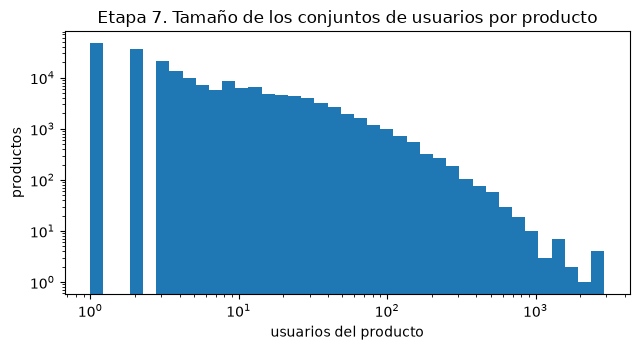

,min_usuarios,productos,fraccion_de_productos,fraccion_de_interacciones
0,1,195008,1.000,1.000
1,2,147916,0.759,0.978
2,3,111240,0.570,0.944
3,5,75953,0.389,0.888
4,10,44521,0.228,0.791
5,20,24556,0.126,0.664
6,50,7964,0.041,0.427


In [2]:
tam = conjuntos.tam
umbrales = [1, 2, 3, 5, 10, 20, 50]
cobertura = pd.DataFrame({"min_usuarios": umbrales, "productos": [int((tam >= u).sum()) for u in umbrales]})
cobertura["fraccion_de_productos"] = cobertura["productos"] / len(tam)
cobertura["fraccion_de_interacciones"] = [tam[tam >= u].sum() / tam.sum() for u in umbrales]
print("Usuarios por producto: mediana {:.0f}, percentil 90 {:.0f}, percentil 99 {:.0f}, máximo {:,}".format(
    *np.percentile(tam, [50, 90, 99]), int(tam.max())))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(tam, bins=np.logspace(0, np.log10(tam.max() + 1), 40))
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("usuarios del producto"); ax.set_ylabel("productos")
ax.set_title("Etapa 7. Tamaño de los conjuntos de usuarios por producto")
fig.tight_layout(); fig.savefig(CARPETA_RESULTADOS / "tamanos_conjuntos.png", dpi=150); plt.show()
cobertura.round(3)

### Efecto de la exclusión de los usuarios bloqueados por la etapa 6

Se comparan los conjuntos sin la exclusión y con ella, con `MIN_USUARIOS`. Primero se cuentan los productos que tienen interacciones de los usuarios bloqueados. En una muestra de esos productos se calculan los K productos de mayor Jaccard exacta en los dos casos y se cuenta cuántas listas cambian, cuántos vecinos se reemplazan y cuántos productos dejan de llegar al mínimo de usuarios. Se usa la fuerza bruta, que es exacta, para que el resultado mida solo el efecto de la exclusión y no el error de LSH.

In [3]:
sin_exclusion = ConjuntosProductos.desde_matriz(RUTA_MATRIZ, (), MIN_USUARIOS)
con_exclusion = ConjuntosProductos.desde_matriz(RUTA_MATRIZ, bloqueados, MIN_USUARIOS)

es_bloqueado = np.isin(np.array(usuarios), list(bloqueados))
marcas = es_bloqueado[sin_exclusion.indices].astype(np.int32)
con_bloqueados = np.add.reduceat(marcas, sin_exclusion.indptr[:-1])        # usuarios bloqueados por producto
tocados = np.flatnonzero(con_bloqueados > 0)
print(f"Con MIN_USUARIOS = {MIN_USUARIOS}: {len(sin_exclusion):,} productos sin la exclusión y "
      f"{len(con_exclusion):,} con ella")
print(f"Productos con interacciones de usuarios bloqueados: {len(tocados):,} "
      f"({len(tocados) / len(sin_exclusion):.2%})")

rng = np.random.default_rng(SEED)
muestra_tocados = rng.choice(tocados, size=min(N_CONSULTAS, len(tocados)), replace=False)
cambian = salen = reemplazados = 0
for i in muestra_tocados.tolist():
    antes = {sin_exclusion.asins[j] for _, j in sin_exclusion.fuerza_bruta(i, K)}
    j = con_exclusion.posicion.obtener(sin_exclusion.asins[i])
    if j is None:
        salen += 1                                 # quedó por debajo de MIN_USUARIOS
        continue
    despues = {con_exclusion.asins[x] for _, x in con_exclusion.fuerza_bruta(j, K)}
    if antes != despues:
        cambian += 1
        reemplazados += len(antes - despues)
evaluados = len(muestra_tocados) - salen
print(f"Muestra de {len(muestra_tocados):,} productos con usuarios bloqueados:")
print(f"  quedan por debajo de MIN_USUARIOS: {salen:,}")
print(f"  cambia su lista de {K} productos relacionados: {cambian:,} de {evaluados:,} ({cambian / max(1, evaluados):.1%})")
print(f"  vecinos reemplazados por lista que cambia: {reemplazados / max(1, cambian):.2f}")

Con MIN_USUARIOS = 5: 76,781 productos sin la exclusión y 75,953 con ella
Productos con interacciones de usuarios bloqueados: 20,406 (26.58%)
Muestra de 1,000 productos con usuarios bloqueados:
  quedan por debajo de MIN_USUARIOS: 40
  cambia su lista de 10 productos relacionados: 901 de 960 (93.9%)
  vecinos reemplazados por lista que cambia: 7.04


### Jaccard de los productos más similares

En una muestra de `N_CONSULTAS` productos se calculan con la fuerza bruta sus K productos de mayor Jaccard. La distribución de esas Jaccard indica qué tan parecidos son en estos datos los productos que la etapa debe encontrar, y con ella se eligen en los pasos 4 y 6 las bandas y filas de LSH.

Fuerza bruta: 27.6 ms por consulta sobre 75,953 productos
Productos de la muestra con 10 vecinos de Jaccard > 0: 83.5%
Jaccard de los vecinos exactos, percentiles [10, 25, 50, 75, 90, 99] : [0.0156, 0.0233, 0.0333, 0.0476, 0.0667, 0.1]


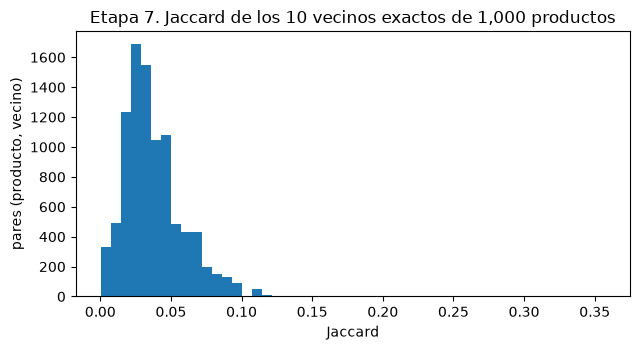

In [4]:
rng = np.random.default_rng(SEED)
muestra = rng.choice(len(con_exclusion), size=min(N_CONSULTAS, len(con_exclusion)), replace=False).tolist()
t0 = time.perf_counter()
exactos = [con_exclusion.fuerza_bruta(i, K) for i in muestra]
ms_fuerza_bruta = (time.perf_counter() - t0) / len(muestra) * 1e3
jaccard_vecinos = np.array([s for lista in exactos for s, _ in lista])

print(f"Fuerza bruta: {ms_fuerza_bruta:.1f} ms por consulta sobre {len(con_exclusion):,} productos")
print(f"Productos de la muestra con {K} vecinos de Jaccard > 0: {sum(len(l) == K for l in exactos) / len(exactos):.1%}")
percentiles = [10, 25, 50, 75, 90, 99]
print("Jaccard de los vecinos exactos, percentiles", percentiles, ":",
      np.round(np.percentile(jaccard_vecinos, percentiles), 4).tolist())

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.hist(jaccard_vecinos, bins=50)
ax.set_xlabel("Jaccard"); ax.set_ylabel("pares (producto, vecino)")
ax.set_title(f"Etapa 7. Jaccard de los {K} vecinos exactos de {len(muestra):,} productos")
fig.tight_layout(); fig.savefig(CARPETA_RESULTADOS / "jaccard_vecinos.png", dpi=150); plt.show()

## Paso 3. MinHash

### Fundamento

Sea h una función que ordena al azar a los usuarios. El mínimo de h sobre U(p) ∪ U(q) es un usuario al azar de la unión, y pertenece a la intersección con probabilidad |U(p) ∩ U(q)| / |U(p) ∪ U(q)|. En ese caso, y solo en ese caso, el mínimo de h sobre U(p) coincide con el mínimo sobre U(q). Por lo tanto

$$P\big[\min h(U(p)) = \min h(U(q))\big] = J(p, q)$$

(Broder, 1997). La **firma** de un producto son los mínimos de n_hashes funciones independientes, y la fracción de posiciones iguales entre dos firmas es un estimador insesgado de J con error estándar √(J(1 − J) / n_hashes). Así, la firma resume un conjunto de cualquier tamaño en n_hashes enteros.

### Funcionamiento en la etapa

Una permutación al azar de 1.1 millones de usuarios no cabe en la práctica para cada función. En su lugar se usa la familia de hash universal de Carter y Wegman (1979), h_i(x) = (a_i·x + b_i) mod p, con p = 2³¹ − 1 primo y a_i, b_i al azar con la semilla. Broder, Charikar, Frieze y Mitzenmacher (2000) estudian cuándo una familia así se comporta como permutaciones al azar. Como a, b y x son menores que 2³¹, a·x + b cabe en un `int64`. `MinHash.firmas` evalúa las funciones sobre todas las interacciones a la vez con numpy y toma el mínimo de cada producto con `np.minimum.reduceat`, en bloques de 8 funciones para acotar la memoria temporal.

### Complejidad

| Operación | Tiempo | Espacio |
| --- | --- | --- |
| Firmas de todos los productos | O(nnz · n_hashes) | O(productos · n_hashes) enteros de 32 bits |
| Jaccard estimada entre dos productos | O(n_hashes) | — |
| Jaccard exacta entre dos productos | O(\|U(p)\| + \|U(q)\|) | — |

### Casos de uso, límites y compromisos

- **Casos de uso.** Detección de documentos casi duplicados en buscadores, que es el uso original en AltaVista (Broder, 1997), deduplicación de datos y recomendación por co-ocurrencia.
- **Límites.** Solo estima Jaccard entre conjuntos sin pesos, así que no distingue una vista de una compra. Con similitudes bajas el error relativo es grande: con J = 0.03 y 128 funciones, el error estándar es 0.015, la mitad del valor, y la firma no coincide en ninguna posición con probabilidad 0.97¹²⁸ ≈ 2 %. Por eso la etapa usa la firma solo para generar candidatos, y los ordena con la Jaccard exacta.
- **Compromiso.** El error baja como 1/√n_hashes, y la memoria y el tiempo de las firmas crecen como n_hashes.

### Error de la estimación según el largo de la firma

La celda calcula las firmas con `N_HASHES` funciones y mide, en los pares (producto, vecino exacto) del paso 2, el error de la Jaccard estimada con firmas de 16 a 512 funciones, frente al error estándar teórico.

Firmas de 75,953 productos con 256 funciones: 8.8 s, 77.8 MB


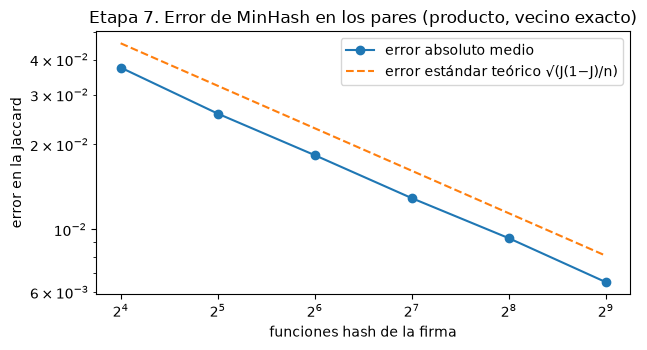

,n_hashes,error_absoluto_medio,error_estandar_teorico_medio,sesgo_medio,fraccion_estimada_cero,memoria_firmas_mb
0,16,0.0375,0.0457,0.0014,0.5603,4.8610
1,32,0.0257,0.0323,-0.0003,0.3597,9.7220
2,64,0.0183,0.0228,0.0003,0.1588,19.4440
3,128,0.0129,0.0161,-0.0001,0.0546,38.8879
4,256,0.0093,0.0114,0.0001,0.0178,77.7759
5,512,0.0065,0.0081,-0.0000,0.0058,155.5517


In [5]:
t0 = time.perf_counter()
firmas = MinHash(N_HASHES, SEED).firmas(con_exclusion.indptr, con_exclusion.indices)
print(f"Firmas de {len(con_exclusion):,} productos con {N_HASHES} funciones: {time.perf_counter() - t0:.1f} s, "
      f"{firmas.nbytes / 1e6:.1f} MB")

pares_i = np.array([i for i, lista in zip(muestra, exactos) for _ in lista])
pares_j = np.array([j for lista in exactos for _, j in lista])
GRILLA_HASHES_ERROR = [16, 32, 64, 128, 256, 512]
filas = []
for n_hashes in GRILLA_HASHES_ERROR:
    f = firmas if n_hashes == N_HASHES else MinHash(n_hashes, SEED).firmas(con_exclusion.indptr, con_exclusion.indices)
    estimada = (f[pares_i] == f[pares_j]).mean(axis=1)
    filas.append({"n_hashes": n_hashes, "error_absoluto_medio": np.abs(estimada - jaccard_vecinos).mean(),
                  "error_estandar_teorico_medio": np.sqrt(jaccard_vecinos * (1 - jaccard_vecinos) / n_hashes).mean(),
                  "sesgo_medio": (estimada - jaccard_vecinos).mean(), "fraccion_estimada_cero": (estimada == 0).mean(),
                  "memoria_firmas_mb": len(con_exclusion) * n_hashes * 4 / 1e6})
error_minhash = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(error_minhash["n_hashes"], error_minhash["error_absoluto_medio"], marker="o", label="error absoluto medio")
ax.plot(error_minhash["n_hashes"], error_minhash["error_estandar_teorico_medio"], ls="--",
        label="error estándar teórico √(J(1−J)/n)")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("funciones hash de la firma"); ax.set_ylabel("error en la Jaccard"); ax.legend()
ax.set_title("Etapa 7. Error de MinHash en los pares (producto, vecino exacto)")
fig.tight_layout(); fig.savefig(CARPETA_RESULTADOS / "minhash_error.png", dpi=150); plt.show()
error_minhash.round(4)

## Paso 4. LSH por bandas

### Fundamento

Comparar las firmas de todos los pares sigue costando O(productos²). LSH (*locality-sensitive hashing*) agrupa los productos de modo que los similares caigan juntos con alta probabilidad y los distintos casi nunca (Indyk y Motwani, 1998). Con MinHash, la técnica es partir la firma en **b bandas de r filas**. Dos productos son candidatos si coinciden en las r filas de al menos una banda. Para dos productos con Jaccard s, una banda coincide con probabilidad s^r, y

$$P[\text{candidatos}] = 1 - (1 - s^r)^b,$$

una curva en S cuyo punto de subida está cerca de (1/b)^(1/r) (Leskovec, Rajaraman y Ullman, 2020, cap. 3). Más filas por banda hacen la curva más empinada y descartan más pares lejanos (el AND dentro de la banda); más bandas la corren hacia similitudes bajas (el OR entre bandas).

### Funcionamiento en la etapa

`LSH` arma las cubetas de cada banda **ordenando** las filas de la banda con `np.unique`, en lugar de una tabla hash. Los productos con los mismos r valores forman una cubeta, sin colisiones entre cubetas distintas. Por banda guarda la cubeta de cada producto y los productos de cada cubeta en tramos contiguos. La consulta de un producto une los productos de sus b cubetas, y `relacionados_lsh` calcula la Jaccard **exacta** de cada candidato y devuelve los K mejores. Así la respuesta nunca tiene un producto con una Jaccard mal estimada: el error de LSH solo puede ser dejar fuera un vecino.

### Complejidad

| Operación | Tiempo | Espacio |
| --- | --- | --- |
| Construcción del índice | O(b · n log n) por el ordenamiento de cada banda | O(b · n) enteros |
| Consulta | O(b + c · \|U\|), con c candidatos y \|U\| su tamaño medio | O(c) |
| Fuerza bruta, una consulta | O(nnz) | O(n_usuarios + nnz) temporal |

### Casos de uso, límites y compromisos

- **Casos de uso.** Búsqueda de casi duplicados en colecciones web, agrupamiento de documentos y generación de candidatos para recomendación.
- **Límites.** Un vecino real puede no caer en ninguna cubeta común, y la probabilidad de perderlo crece cuando su Jaccard está por debajo del punto de subida de la curva. El índice ocupa b enteros por producto. Una cubeta con muchos productos, por ejemplo de firmas que coinciden por azar, aumenta los candidatos que hay que verificar.
- **Compromiso.** Bajar el punto de subida encuentra vecinos menos similares a costa de más candidatos por consulta, y con n_hashes fijo, b · r = n_hashes.

### Curvas en S frente a la Jaccard de los vecinos exactos

La celda dibuja la curva de todas las particiones b × r de una firma de `N_HASHES` funciones sobre la distribución del paso 2. La tabla da, para cada partición, la probabilidad media de que un vecino exacto sea candidato, que es la cota del recall que puede alcanzar. El paso 6 mide el recall real de todas las particiones con firmas de 32 a 256 funciones.

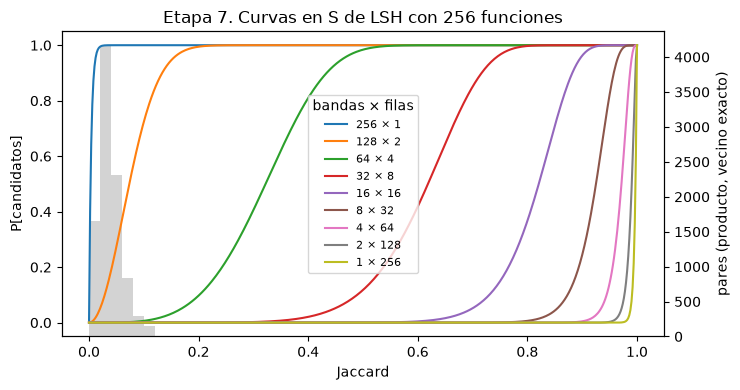

,bandas,filas,umbral_aprox,prob_media_vecino_candidato,prob_en_la_mediana
0,256,1,0.0039,0.9833,0.9998
1,128,2,0.0884,0.1884,0.1326
2,64,4,0.3536,0.0007,0.0001
3,32,8,0.6484,0.0000,0.0000
4,16,16,0.8409,0.0000,0.0000
5,8,32,0.9371,0.0000,0.0000
6,4,64,0.9786,0.0000,0.0000
7,2,128,0.9946,0.0000,0.0000
8,1,256,1.0000,0.0000,0.0000


Índice LSH 256 × 1: 19.8 s, 215.4 MB
Producto: Rainbow Color Pen - 12 Pack of 6-in-1 Multi Color Ink Gel Pens 0.8mm Roller Ball Office Sc
Candidatos LSH: 8 de 75,953 productos; recall@10 frente a la fuerza bruta: 1.00


,jaccard,producto relacionado
0,0.0769,Keyboard Wrist Rest + Mouse Pad + Mouse Wrist ...
1,0.0625,Hallmark St. Patricks Day Card (Perfectly Happy)
2,0.0370,Dxhycc 32 PCS 1 Set Vintage Retro Old Travel P...
3,0.0312,220XL 220XL T220XL Remanufactured for Epson 22...
4,0.0161,500-Pack Self-Adhesive Baby Bottle Labels for ...
5,0.0122,"BIC Glide Black Retractable Ballpoint Pens, Me..."
6,0.0064,Shine glitter gel pen 10 pk - Assorted
7,0.0045,Paper Mate InkJoy 300RT Retractable Ballpoint ...


In [6]:
def configuraciones_lsh(n_hashes):
    """Todas las particiones de una firma de n_hashes funciones en bandas × filas."""
    return [(n_hashes // r, r) for r in range(1, n_hashes + 1) if n_hashes % r == 0]


s = np.linspace(0, 1, 501)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax_hist = ax.twinx()
ax_hist.hist(jaccard_vecinos, bins=50, range=(0, 1), color="lightgray")
ax_hist.set_ylabel("pares (producto, vecino exacto)")
ax.set_zorder(ax_hist.get_zorder() + 1); ax.patch.set_visible(False)
filas = []
for bandas, filas_banda in configuraciones_lsh(N_HASHES):
    ax.plot(s, LSH.probabilidad(s, bandas, filas_banda), label=f"{bandas} × {filas_banda}")
    filas.append({"bandas": bandas, "filas": filas_banda, "umbral_aprox": LSH.umbral(bandas, filas_banda),
                  "prob_media_vecino_candidato": float(LSH.probabilidad(jaccard_vecinos, bandas, filas_banda).mean()),
                  "prob_en_la_mediana": float(LSH.probabilidad(np.median(jaccard_vecinos), bandas, filas_banda))})
ax.set_xlabel("Jaccard"); ax.set_ylabel("P[candidatos]"); ax.legend(title="bandas × filas", fontsize=8)
ax.set_title(f"Etapa 7. Curvas en S de LSH con {N_HASHES} funciones")
fig.tight_layout(); fig.savefig(CARPETA_RESULTADOS / "lsh_curvas.png", dpi=150); plt.show()
display(pd.DataFrame(filas).round(4))

# Índice con los parámetros del módulo y una consulta de ejemplo
t0 = time.perf_counter()
lsh = LSH(firmas, BANDAS, FILAS)
print(f"Índice LSH {BANDAS} × {FILAS}: {time.perf_counter() - t0:.1f} s, {lsh.memoria_bytes / 1e6:.1f} MB")
i = muestra[0]
relacionados = relacionados_lsh(con_exclusion, lsh, i, K)
print(f"Producto: {titulo[con_exclusion.asins[i]]}")
print(f"Candidatos LSH: {lsh.candidatos_evaluados:,} de {len(con_exclusion):,} productos; "
      f"recall@{K} frente a la fuerza bruta: {recall_at_k(relacionados, exactos[0]):.2f}")
pd.DataFrame([{"jaccard": round(s, 4), "producto relacionado": titulo[con_exclusion.asins[j]]} for s, j in relacionados])

## Paso 5. Vectores de atributos y HNSW

### Vectores de atributos

El campo `category` del evento, que la etapa 1 reserva para la similitud de la etapa 7, es la `main_category` del producto. La celda muestra que en esta categoría casi todos los productos tienen el mismo valor, así que no distingue productos. Por eso los rasgos se toman del catálogo de la etapa 3: las **palabras del título** (en minúsculas, de dos o más caracteres), la **categoría de último nivel** y la **tienda**.

`MatrizTFIDF` construye el vector de cada producto en tres pasos.

1. **Hashing trick.** Cada rasgo va a la columna `hash_clave(rasgo) mod 2¹⁸`, con el CRC32 de la etapa 3, sin guardar un vocabulario (Weinberger et al., 2009).
2. **TF-IDF.** El peso de una columna en un producto es (1 + ln tf) · ln(n / df), que baja el peso de las palabras que aparecen en muchos productos (Salton y Buckley, 1988). Cada fila se divide por su norma, así que el producto punto entre dos filas es el coseno.
3. **Reducción a DIM dimensiones**, con uno de dos métodos, y normalización a norma 1. Entre vectores de norma 1, ‖x − y‖² = 2 − 2·cos(x, y), así que la distancia euclidiana ordena igual que el coseno.
   - **Proyección aleatoria** (`"proyeccion"`). Se multiplica por una matriz gaussiana de 2¹⁸ × DIM. Conserva aproximadamente las distancias de cualquier conjunto de puntos (Johnson y Lindenstrauss, 1984), pero para hacerlo con error ε necesita del orden de log n / ε² dimensiones, porque no aprovecha la estructura de los datos.
   - **SVD truncada** (`"svd"`, análisis semántico latente; Deerwester et al., 1990). Representa cada producto en las DIM direcciones de mayor varianza de la matriz, que es la mejor aproximación de rango DIM (Eckart y Young, 1936). Las palabras que aparecen juntas en los títulos se combinan en las mismas direcciones. Se calcula con la SVD aleatorizada de Halko, Martinsson y Tropp (2011): una proyección gaussiana a DIM + 10 columnas, dos iteraciones de potencia y una descomposición de una matriz pequeña. Los productos por la matriz dispersa (`por_derecha` y `por_izquierda`) usan su formato CSR y CSC, sin scipy, en O(nnz · DIM).

La línea base de la reducción es el **coseno exacto en el espacio TF-IDF**: `coseno_contra_todos` suma, para cada columna del producto, los pesos de los productos que la contienen (formato CSC). El paso 6 mide cuántos de los K vecinos de ese coseno exacto conserva cada método en cada dimensión.

### HNSW

**Fundamento.** Un grafo de mundo pequeño navegable (NSW) conecta cada punto con puntos cercanos y con algunos lejanos, así que una búsqueda voraz que siempre salta al vecino más cercano a la consulta llega rápido a su zona (Malkov et al., 2014). HNSW separa esas aristas por escala en capas, como una skip list. Cada punto recibe un nivel máximo l = ⌊−ln(U) · mL⌋, con U uniforme y mL = 1/ln(M), así que cada capa tiene en promedio 1/M de los puntos de la anterior. La búsqueda baja de forma voraz desde la capa superior, con pocos puntos y aristas largas, hasta la capa 0, que tiene todos los puntos (Malkov y Yashunin, 2020).

**Funcionamiento en la etapa** (`HNSW` en `src/etapa_7/similarity.py`, con los algoritmos del paper):

- **Búsqueda en una capa (algoritmo 2).** Mantiene los candidatos por expandir en un `MinHeap` de la etapa 2 y los `ef` mejores resultados en otro `MinHeap` con la distancia negada, para que la raíz sea el peor. Expande el candidato más cercano y se detiene cuando ese candidato está más lejos que el peor resultado. Las distancias a los vecinos nuevos de un nodo se calculan de una vez con numpy.
- **Inserción (algoritmo 1).** Baja de forma voraz (ef = 1) hasta el nivel del punto, y en cada capa desde ahí busca `ef_construccion` candidatos y conecta el punto con M de ellos (2·M en la capa 0). Si un vecino supera su máximo de aristas, se recortan las suyas con la misma regla.
- **Selección de vecinos.** `"simple"` (algoritmo 3) toma los M candidatos más cercanos. `"heuristica"` (algoritmo 4) acepta un candidato solo si está más cerca del punto nuevo que de todos los vecinos ya aceptados, lo que conserva aristas hacia regiones distintas. El paso 6 compara las dos.

**Línea base exacta.** `similares_exactos` usa `knn_fuerza_bruta` de la etapa 5, que calcula la distancia a todos los vectores, O(n · d) por consulta. El KNN exacto con índice es el `KDTree` de la etapa 5; su experimento B mostró que desde d = 16 evalúa casi todos los puntos, y el paso 9 lo mide con d = DIM.

### Complejidad

| Operación | Tiempo | Espacio |
| --- | --- | --- |
| Vectores TF-IDF y proyección aleatoria | O(rasgos · DIM) | O(productos · DIM) |
| SVD aleatorizada | O(rasgos · DIM) por producto con la matriz, más O((productos + columnas) · DIM²) de las QR | O((productos + columnas) · DIM) |
| Construcción de HNSW | O(n log n) esperado (empírico en el paper) | O(n · (DIM + M)) |
| Consulta de HNSW | O(log n) esperado, con O(ef · M) distancias por capa | O(ef) |
| Fuerza bruta, una consulta | O(n · DIM) | O(n · DIM) temporal |
| KD-Tree, una consulta | O(log n) en dimensión baja, O(n) en dimensión alta | O(n) |

### Casos de uso, límites y compromisos

- **Casos de uso.** Búsqueda de vecinos de *embeddings* en recomendación, búsqueda semántica y bases de datos vectoriales. HNSW está entre los métodos con mejor relación entre recall y consultas por segundo en ANN-Benchmarks (Aumüller, Bernhardsson y Faithfull, 2020).
- **Límites.** Guarda los vectores completos más M a 2·M aristas por punto, así que ocupa más memoria que un índice comprimido como IVF con cuantización (Jégou, Douze y Schmid, 2011). No da garantía de encontrar el vecino exacto, y borrar puntos no es directo. En Python puro la construcción es lenta, porque cada inserción hace cientos de operaciones de heap.
- **Compromiso.** M y `ef_construccion` mejoran el grafo a costa de tiempo de construcción y memoria; `ef` de búsqueda sube el recall a costa de tiempo por consulta. El paso 6 mide esas curvas.

La celda revisa la `main_category`, construye la matriz TF-IDF y los vectores con `DIM` dimensiones y el método `REDUCCION`, y compara para tres productos sus vecinos por coseno exacto en TF-IDF con sus vecinos exactos en los vectores reducidos.

In [7]:
principal = Counter(r.get("main_category") for r in registros)
mas_frecuente, veces = principal.most_common(1)[0]
print(f"main_category: {len(principal)} valores; el más frecuente, {mas_frecuente!r}, en {veces / len(registros):.1%} "
      f"de los productos")
print(f"Categoría de último nivel: {len({r.get('categoria_hoja') for r in registros}):,} valores")

t0 = time.perf_counter()
tfidf = MatrizTFIDF(registros)
t_tfidf = time.perf_counter() - t0
t0 = time.perf_counter()
V = tfidf.reducir(DIM, REDUCCION, SEED)
t_proyeccion = time.perf_counter() - t0
print(f"TF-IDF: {len(tfidf.peso):,} pesos distintos de cero en {tfidf.n:,} productos "
      f"({len(tfidf.peso) / tfidf.n:.1f} por producto), {t_tfidf:.1f} s")
print(f"Reducción con {REDUCCION} a DIM = {DIM}: {t_proyeccion:.1f} s, {V.nbytes / 1e6:.1f} MB; "
      f"productos sin rasgos: {int((np.linalg.norm(V, axis=1) == 0).sum()):,}")

rng = np.random.default_rng(SEED)
tablas = []
for i in rng.choice(tfidf.n, size=3, replace=False).tolist():
    coseno = tfidf.similares_exactos(i, 5)
    proyectado = similares_exactos(V, i, 5)
    tablas.append(pd.DataFrame({
        "consulta": [titulo[productos[i]]] + [""] * 4,
        "vecino por coseno exacto (TF-IDF)": [f"{c:.2f} {titulo[productos[j]]}" for c, j in coseno],
        f"vecino exacto en DIM = {DIM} ({REDUCCION})": [f"{d:.2f} {titulo[productos[j]]}" for d, j in proyectado]}))
pd.concat(tablas, ignore_index=True)

main_category: 35 valores; el más frecuente, 'Office Products', en 65.2% de los productos
Categoría de último nivel: 576 valores
TF-IDF: 3,819,587 pesos distintos de cero en 195,019 productos (19.6 por producto), 4.3 s
Reducción con proyeccion a DIM = 128: 5.9 s, 99.8 MB; productos sin rasgos: 0


,consulta,vecino por coseno exacto (TF-IDF),vecino exacto en DIM = 128 (proyeccion)
0,"Steam Trains Mini Wall Calendar 2023, 7"" x 7""",0.60 2023 Steam Trains Monthly Wall Calendar b...,"0.92 Italy Mini Wall Calendar 2023, 7"" x 7"""
1,,"0.59 Cats Mini Wall Calendar 2023, 7"" x 7""",0.98 2023 Steam Trains Monthly Wall Calendar b...
2,,"0.56 Travel the World Mini Wall Calendar 2023,...","0.98 Travel the World Mini Wall Calendar 2023,..."
3,,"0.55 Italy Mini Wall Calendar 2023, 7"" x 7""","0.99 Cats Mini Wall Calendar 2023, 7"" x 7"""
4,,"0.55 Monet Mini Wall Calendar 2023, 7"" x 7"".","1.00 Wolves Mini Wall Calendar 2023, 7"" x 7"""
5,500 Count Rubber Bands in Re-closable Containe...,0.25 AMUU Rubber Bands1200pcs white small Rubb...,1.07 Olwaiy Wrist Keychain for Women & Men Key...
6,,"0.25 Small Rubber Bands for Hair, 1500 Pcs Bla...",1.10 (BE) 6 Pack M855 Magazine Marking Bands A...
7,,0.24 ONLYKXY 300pcs White Natural Rubber Bands...,1.11 YOUOWO Wrist lanyards 4 Pack PU Black Lea...
8,,0.23 Diane D6771 Black Rubber Bands for Hair S...,1.11 Alliance Rubber Company Inc. Can Bands 7-...
9,,0.23 VAGA 600 Mini Rubber Bands Soft Elastic B...,1.12 Car Key Lanyard Wrist Lanyards for Keys W...


## Paso 6. Elección de parámetros

Cada parámetro de la etapa se elige comparando **todas** sus alternativas en una grilla completa, no moviendo un parámetro con los demás fijos. Las grillas se miden una vez sobre los datos reales, con `N_CONSULTAS` consultas por configuración, porque su objetivo es comparar configuraciones entre sí; los tiempos con 100 repeticiones y de 1K a 1M son los del paso 9, con la configuración elegida.

| Grilla | Parámetros comparados | Medidas |
| --- | --- | --- |
| 6.1 Conjuntos | mínimo de usuarios ∈ {2, 3, 5, 10, 20} × funciones ∈ {32, 64, 128, 256} × todas las particiones bandas × filas de cada firma | Productos cubiertos, recall@K frente a la fuerza bruta, candidatos y ms por consulta, tiempo de las firmas y del índice, memoria |
| 6.2 Vectores | método de reducción ∈ {proyección aleatoria, SVD} × DIM ∈ {16, 32, 64, 128, 256} | Recall@K de la búsqueda exacta en los vectores reducidos frente al coseno exacto en TF-IDF, tiempo de la reducción y de la consulta, memoria |
| 6.3 HNSW | M ∈ {8, 16, 32} × `ef_construccion` ∈ {50, 100, 200} × selección ∈ {heurística, simple}, y para cada índice `ef` de búsqueda ∈ {10, 20, 50, 100, 200} | Tiempo de construcción, memoria, recall@K frente a la fuerza bruta, distancias y ms por consulta |

En 6.1 la fuerza bruta de cada mínimo de usuarios se calcula una vez, y sus respuestas son la referencia de todas las particiones. En 6.3 los índices se construyen sobre `N_GRILLA_HNSW` vectores reales elegidos con la semilla, porque cada construcción en Python cuesta varios minutos; la celda imprime el tiempo de cada una.

**Cómo se fijan los parámetros.** Los valores de `src/etapa_7/similarity.py` se fijan con estas grillas; los de conjuntos con 6.1, los de los vectores con 6.2 y los de HNSW con 6.3. Después de leer estas grillas se fijan en el módulo con la justificación en el texto, como el umbral de la etapa 6, y se vuelve a ejecutar el notebook. Los pasos 7 a 9 se ejecutan recién con los parámetros fijados. Las grillas guardadas se reutilizan, y los archivos de los pasos 6.3 y 9 llevan en el nombre los parámetros con que se midieron, así que se miden de nuevo si cambian. La grilla 6.3 depende de DIM y del método de reducción, así que se ejecuta después de fijarlos con 6.2.

La celda siguiente define las funciones de medición que comparten los pasos 6 y 9.

In [ ]:
import gc
import statistics
import tracemalloc

# Las mediciones guardadas en results/etapa_7/ se reutilizan. Con True se miden de nuevo.
REEJECUTAR_EXPERIMENTOS = False
R = CARPETA_RESULTADOS


def resultados(ruta, medir_tabla, requeridas=()):
    """Lee la tabla de resultados si existe y tiene las columnas `requeridas`. Si no, la mide con
    medir_tabla() y la guarda con la plataforma."""
    if ruta.exists() and not REEJECUTAR_EXPERIMENTOS:
        tabla = pd.read_csv(ruta, dtype={"procesador": str, "python": str})
        if all(c in tabla.columns for c in requeridas):
            print(f"Resultados leídos de {ruta.name}")
            return tabla
        print(f"{ruta.name} es de una versión anterior del experimento y se mide de nuevo")
    tabla = medir_tabla().assign(procesador=PLATAFORMA["procesador"], python=PLATAFORMA["python"])
    tabla.to_csv(ruta, index=False)
    print(f"Resultados guardados en {ruta.name}")
    return tabla


def plataforma_de(tabla):
    """Procesador y versión de Python con que se midió una tabla de resultados."""
    return f"{tabla['procesador'].iloc[0]}, Python {tabla['python'].iloc[0]}"


def medir(funcion, *args):
    """(segundos, resultado) de funcion(*args), con el recolector de basura desactivado.

    El resultado se devuelve para que la estructura se libere fuera del intervalo medido.
    """
    gc.collect()
    gc.disable()
    try:
        t0 = time.perf_counter()
        resultado = funcion(*args)
        segundos = time.perf_counter() - t0
    finally:
        gc.enable()
    return segundos, resultado


def medir_memoria(funcion, *args):
    """(resultado, memoria actual, memoria pico) en bytes. Solo se rastrea lo que asigna funcion."""
    gc.collect()
    tracemalloc.start()
    resultado = funcion(*args)
    actual, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return resultado, actual, pico

### 6.1 Conjuntos: mínimo de usuarios, largo de la firma y bandas × filas

Para cada mínimo de usuarios se cargan los conjuntos, se elige una muestra de `N_CONSULTAS` productos con la semilla y se calculan sus K vecinos exactos. Para cada largo de firma se calculan las firmas, y para cada partición bandas × filas se construye el índice y se responden las mismas consultas. El recall@K es la fracción de los vecinos exactos que aparecen en la respuesta de LSH. Un producto que no comparte usuarios con ningún otro no tiene vecinos exactos, y su recall no está definido: esas consultas se cuentan en `consultas_sin_vecinos` y no entran en el promedio.

Resultados leídos de grilla_conjuntos.csv


,productos,nnz,jaccard_vecinos_mediana,fraccion_con_k_vecinos,consultas_sin_vecinos,ms_consulta_fuerza_bruta
min_usuarios,,,,,,
2,147916,2086510,0.0400,0.538,21,33.1041
3,111240,2013158,0.0357,0.706,10,35.2897
5,75953,1893653,0.0333,0.835,2,27.7266
10,44521,1688010,0.0260,0.972,0,27.3538
20,24556,1417135,0.0197,0.999,0,27.1215


min_usuarios           2      3      5      10     20
n_hashes particion                                   
32       32 × 1     0.655  0.661  0.634  0.571  0.484
         16 × 2     0.081  0.053  0.029  0.017  0.008
         8 × 4      0.003  0.000  0.000  0.000  0.000
         4 × 8      0.000  0.000  0.000  0.000  0.000
         2 × 16     0.000  0.000  0.000  0.000  0.000
         1 × 32     0.000  0.000  0.000  0.000  0.000
64       64 × 1     0.810  0.827  0.832  0.800  0.722
         32 × 2     0.140  0.101  0.054  0.027  0.017
         16 × 4     0.005  0.001  0.000  0.000  0.000
         8 × 8      0.000  0.000  0.000  0.000  0.000
         4 × 16     0.000  0.000  0.000  0.000  0.000
         2 × 32     0.000  0.000  0.000  0.000  0.000
         1 × 64     0.000  0.000  0.000  0.000  0.000
128      128 × 1    0.907  0.919  0.940  0.946  0.915
         64 × 2     0.209  0.153  0.108  0.054  0.033
         32 × 4     0.010  0.002  0.001  0.000  0.000
         16 × 8     0.000  0.000  0.000  0.000  0.000
         8 × 16     0.000  0.000  0.000  0.000  0.000
         4 × 32     0.000  0.000  0.000  0.000  0.000
         2 × 64     0.000  0.000  0.000  0.000  0.000
         1 × 128    0.000  0.000  0.000  0.000  0.000
256      256 × 1    0.957  0.971  0.979  0.989  0.989
         128 × 2    0.297  0.253  0.197  0.098  0.062
         64 × 4     0.016  0.002  0.000  0.000  0.000
         32 × 8     0.000  0.000  0.000  0.000  0.000
         16 × 16    0.000  0.000  0.000  0.000  0.000
         8 × 32     0.000  0.000  0.000  0.000  0.000
         4 × 64     0.000  0.000  0.000  0.000  0.000
         2 × 128    0.000  0.000  0.000  0.000  0.000
         1 × 256    0.000  0.000  0.000  0.000  0.000

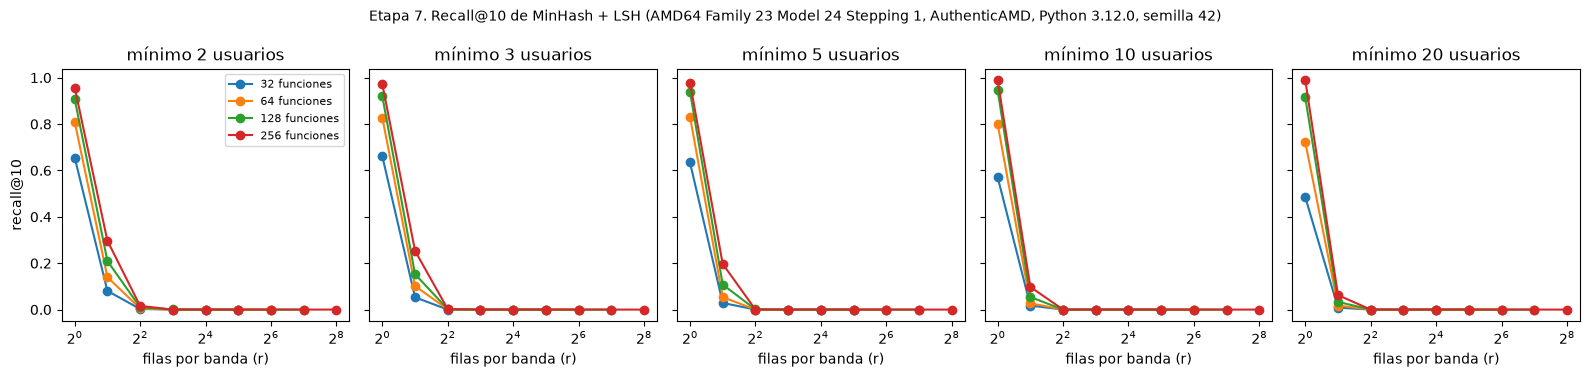

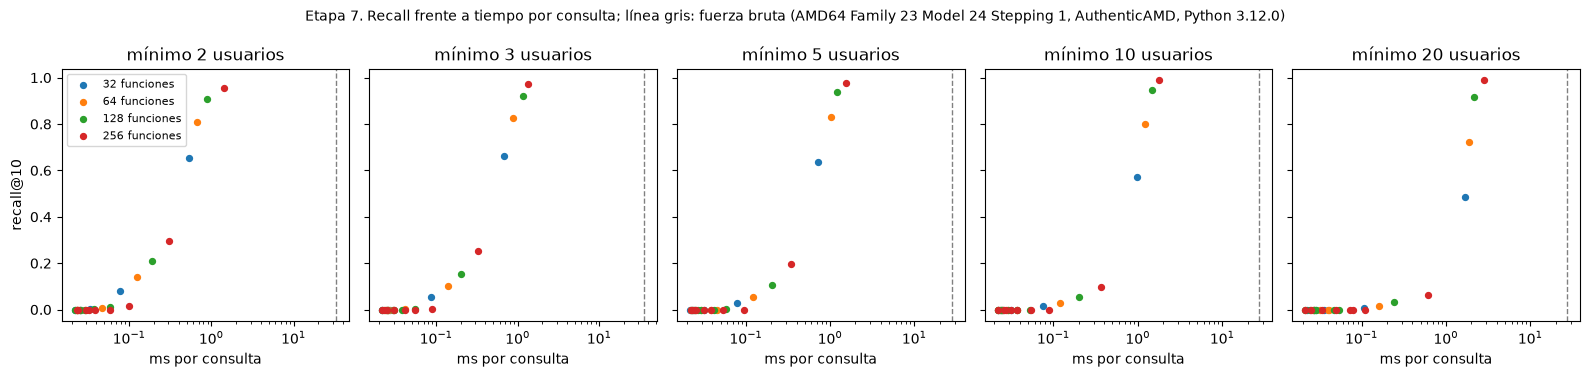

In [9]:
GRILLA_MIN_USUARIOS = [2, 3, 5, 10, 20]
GRILLA_HASHES = [32, 64, 128, 256]


def experimento_grilla_conjuntos():
    filas = []
    for min_usuarios in GRILLA_MIN_USUARIOS:
        t_inicio = time.perf_counter()
        c = ConjuntosProductos.desde_matriz(RUTA_MATRIZ, bloqueados, min_usuarios)
        consultas = np.random.default_rng(SEED).choice(len(c), size=min(N_CONSULTAS, len(c)), replace=False).tolist()
        t0 = time.perf_counter()
        referencia = [c.fuerza_bruta(i, K) for i in consultas]
        ms_bruta = (time.perf_counter() - t0) / len(consultas) * 1e3
        jaccard_ref = [s for lista in referencia for s, _ in lista]
        for n_hashes in GRILLA_HASHES:
            t0 = time.perf_counter()
            f = MinHash(n_hashes, SEED).firmas(c.indptr, c.indices)
            s_firmas = time.perf_counter() - t0
            for bandas, filas_banda in configuraciones_lsh(n_hashes):
                t0 = time.perf_counter()
                indice = LSH(f, bandas, filas_banda)
                s_indice = time.perf_counter() - t0
                recall, candidatos, t_consulta = [], 0, 0.0
                for i, exacto in zip(consultas, referencia):
                    t0 = time.perf_counter()
                    aproximado = relacionados_lsh(c, indice, i, K)
                    t_consulta += time.perf_counter() - t0
                    candidatos += indice.candidatos_evaluados
                    recall.append(recall_at_k(aproximado, exacto))
                filas.append({"min_usuarios": min_usuarios, "productos": len(c), "nnz": c.nnz,
                              "n_hashes": n_hashes, "bandas": bandas, "filas": filas_banda,
                              "umbral_aprox": LSH.umbral(bandas, filas_banda), "consultas": len(consultas),
                              "recall_at_k": float(np.nanmean(recall)),
                              "consultas_sin_vecinos": int(np.isnan(recall).sum()),
                              "candidatos_por_consulta": candidatos / len(consultas),
                              "ms_consulta_lsh": t_consulta / len(consultas) * 1e3, "ms_consulta_fuerza_bruta": ms_bruta,
                              "segundos_firmas": s_firmas, "segundos_indice": s_indice,
                              "memoria_firmas_bytes": f.nbytes, "memoria_indice_bytes": indice.memoria_bytes,
                              "jaccard_vecinos_mediana": float(np.median(jaccard_ref)),
                              "fraccion_con_k_vecinos": float(np.mean([len(l) == K for l in referencia]))})
                del indice
            del f
        print(f"Mínimo de usuarios {min_usuarios}: {len(c):,} productos, {time.perf_counter() - t_inicio:.0f} s", flush=True)
    return pd.DataFrame(filas)


grilla_conjuntos = resultados(R / "grilla_conjuntos.csv", experimento_grilla_conjuntos, ["consultas_sin_vecinos"])

# Cobertura y calidad de la referencia según el mínimo de usuarios
display(grilla_conjuntos.groupby("min_usuarios")[["productos", "nnz", "jaccard_vecinos_mediana",
                                                   "fraccion_con_k_vecinos", "consultas_sin_vecinos",
                                                   "ms_consulta_fuerza_bruta"]].first().round(4))

# Recall@K de todas las configuraciones
tabla = grilla_conjuntos.assign(particion=grilla_conjuntos["bandas"].astype(str) + " × " + grilla_conjuntos["filas"].astype(str))
display(tabla.pivot_table(index=["n_hashes", "particion"], columns="min_usuarios", values="recall_at_k", sort=False).round(3))

fig, axes = plt.subplots(1, len(GRILLA_MIN_USUARIOS), figsize=(16, 3.8), sharey=True)
for ax, (min_usuarios, datos) in zip(axes, grilla_conjuntos.groupby("min_usuarios")):
    for n_hashes, d in datos.groupby("n_hashes"):
        ax.plot(d["filas"], d["recall_at_k"], marker="o", label=f"{n_hashes} funciones")
    ax.set_xscale("log", base=2); ax.set_xlabel("filas por banda (r)"); ax.set_title(f"mínimo {min_usuarios} usuarios")
axes[0].set_ylabel(f"recall@{K}"); axes[0].legend(fontsize=8)
fig.suptitle(f"Etapa 7. Recall@{K} de MinHash + LSH ({plataforma_de(grilla_conjuntos)}, semilla {SEED})", fontsize=10)
fig.tight_layout(); fig.savefig(R / "grilla_conjuntos_recall.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, len(GRILLA_MIN_USUARIOS), figsize=(16, 3.8), sharey=True)
for ax, (min_usuarios, datos) in zip(axes, grilla_conjuntos.groupby("min_usuarios")):
    for n_hashes, d in datos.groupby("n_hashes"):
        ax.scatter(d["ms_consulta_lsh"], d["recall_at_k"], label=f"{n_hashes} funciones", s=18)
    ax.axvline(datos["ms_consulta_fuerza_bruta"].iloc[0], color="gray", ls="--", lw=1)
    ax.set_xscale("log"); ax.set_xlabel("ms por consulta"); ax.set_title(f"mínimo {min_usuarios} usuarios")
axes[0].set_ylabel(f"recall@{K}"); axes[0].legend(fontsize=8)
fig.suptitle(f"Etapa 7. Recall frente a tiempo por consulta; línea gris: fuerza bruta "
             f"({plataforma_de(grilla_conjuntos)})", fontsize=10)
fig.tight_layout(); fig.savefig(R / "grilla_conjuntos_tiempo.png", dpi=150); plt.show()

**Elección de los parámetros de conjuntos.**

- **Filas por banda: `FILAS = 1`.** Con dos filas o más, el recall@K no pasa de 0.30 en ninguna combinación. La Jaccard de los vecinos exactos tiene mediana 0.033 (paso 2), muy por debajo del punto de subida de cualquier partición con r ≥ 2, que con 256 funciones es 0.088 o más (128 × 2). Con una fila por banda, un vecino de Jaccard J es candidato con probabilidad 1 − (1 − J)^b, y LSH queda solo con la amplificación OR entre bandas. No es una decisión de diseño sino una consecuencia de que en estos datos los productos relacionados comparten pocos usuarios.
- **Largo de la firma: `N_HASHES = 256`, con `BANDAS = 256`.** Con un mínimo de 5 usuarios, el recall@K es 0.634 con 32 funciones, 0.832 con 64, 0.940 con 128 y 0.979 con 256. Pasar de 128 a 256 cuesta 0.3 ms más por consulta (1.54 frente a 1.22 ms), el doble de memoria (293 frente a 147 MB entre firmas e índice) y el doble de construcción (27 frente a 14 s). Las dos quedan unas 18 veces por debajo de los 27.7 ms de la fuerza bruta, que cuesta O(nnz) por consulta, y LSH verifica unos 55 candidatos de 75 953 productos.
- **Mínimo de usuarios: `MIN_USUARIOS = 5`.** Con 256 funciones el recall@K casi no depende del mínimo (de 0.957 con 2 a 0.989 con 20). Lo que cambia es la cobertura frente a la calidad de la referencia. Con 2 usuarios se compara el 75.9 % de los productos y el 97.8 % de las interacciones, pero solo el 53.8 % de las consultas tiene K vecinos de Jaccard > 0 y 21 de 1 000 no tienen ninguno, porque la Jaccard entre conjuntos de 2 o 3 usuarios solo toma unos pocos valores. Con 5 usuarios se compara el 38.9 % de los productos, que concentran el 88.8 % de las interacciones, el 83.5 % de las consultas tiene K vecinos y solo 2 no tienen ninguno. Con 20 usuarios la cobertura baja al 66.4 % de las interacciones. Los productos con menos de 5 usuarios reciben sus productos similares por atributos (HNSW).

### 6.2 Vectores: método de reducción y dimensión

Para cada método y cada dimensión se reduce la misma matriz TF-IDF y se buscan, con la fuerza bruta exacta, los K vecinos de `N_CONSULTAS` productos. La referencia son los K vecinos por coseno exacto en TF-IDF. Así se mide solo la pérdida de la reducción, sin el error de HNSW. Una dimensión mayor conserva más vecinos, pero cada distancia y cada vector cuestan más. La celda también muestra el tiempo de la consulta exacta en TF-IDF con las listas por columna, que es la alternativa exacta sin reducir.

Resultados leídos de grilla_dimension.csv


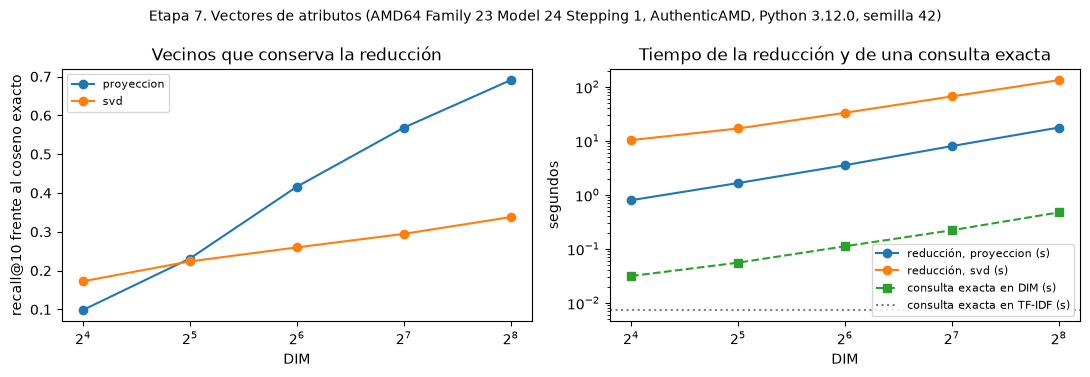

recall_at_k         segundos_reduccion          
metodo  proyeccion     svd         proyeccion       svd
dim                                                    
16          0.0985  0.1725             0.7946   10.3065
32          0.2311  0.2237             1.6501   16.9112
64          0.4161  0.2598             3.5320   33.0146
128         0.5681  0.2946             7.9773   66.2918
256         0.6906  0.3378            17.5967  132.7036

In [10]:
GRILLA_REDUCCION = ["proyeccion", "svd"]
GRILLA_DIM = [16, 32, 64, 128, 256]


def experimento_grilla_dimension():
    consultas = np.random.default_rng(SEED).choice(tfidf.n, size=N_CONSULTAS, replace=False).tolist()
    t0 = time.perf_counter()
    referencia = [tfidf.similares_exactos(i, K) for i in consultas]
    ms_coseno = (time.perf_counter() - t0) / len(consultas) * 1e3
    filas = []
    for metodo, dim in product(GRILLA_REDUCCION, GRILLA_DIM):
        t0 = time.perf_counter()
        Vd = tfidf.reducir(dim, metodo, SEED)
        s_reduccion = time.perf_counter() - t0
        t0 = time.perf_counter()
        respuestas = [similares_exactos(Vd, i, K) for i in consultas]
        ms_bruta = (time.perf_counter() - t0) / len(consultas) * 1e3
        recall = [recall_at_k(a, e) for a, e in zip(respuestas, referencia)]
        filas.append({"metodo": metodo, "dim": dim, "consultas": len(consultas),
                      "consultas_sin_vecinos": int(np.isnan(recall).sum()), "recall_at_k": float(np.nanmean(recall)),
                      "segundos_reduccion": s_reduccion, "ms_consulta_fuerza_bruta": ms_bruta,
                      "ms_consulta_coseno_tfidf": ms_coseno, "memoria_vectores_bytes": Vd.nbytes})
        del Vd
        print(f"{metodo}, DIM = {dim}: reducción {s_reduccion:.1f} s", flush=True)
    return pd.DataFrame(filas)


grilla_dimension = resultados(R / "grilla_dimension.csv", experimento_grilla_dimension, ["metodo"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for metodo, d in grilla_dimension.groupby("metodo", sort=False):
    ax1.plot(d["dim"], d["recall_at_k"], marker="o", label=metodo)
    ax2.plot(d["dim"], d["segundos_reduccion"], marker="o", label=f"reducción, {metodo} (s)")
ax1.set_xscale("log", base=2); ax1.set_xlabel("DIM"); ax1.set_ylabel(f"recall@{K} frente al coseno exacto")
ax1.set_title("Vecinos que conserva la reducción"); ax1.legend(fontsize=8)
d = grilla_dimension[grilla_dimension["metodo"] == GRILLA_REDUCCION[0]]
ax2.plot(d["dim"], d["ms_consulta_fuerza_bruta"] / 1e3, marker="s", ls="--", label="consulta exacta en DIM (s)")
ax2.axhline(grilla_dimension["ms_consulta_coseno_tfidf"].iloc[0] / 1e3, color="gray", ls=":",
            label="consulta exacta en TF-IDF (s)")
ax2.set_xscale("log", base=2); ax2.set_yscale("log"); ax2.set_xlabel("DIM"); ax2.set_ylabel("segundos")
ax2.set_title("Tiempo de la reducción y de una consulta exacta"); ax2.legend(fontsize=8)
fig.suptitle(f"Etapa 7. Vectores de atributos ({plataforma_de(grilla_dimension)}, semilla {SEED})", fontsize=10)
fig.tight_layout(); fig.savefig(R / "grilla_dimension.png", dpi=150); plt.show()
grilla_dimension.pivot_table(index="dim", columns="metodo", values=["recall_at_k", "segundos_reduccion"]).round(4)

**Elección de los vectores.**

- **Método: `REDUCCION = "proyeccion"`.** La SVD conserva menos vecinos que la proyección aleatoria en todas las dimensiones desde 32: 0.260 frente a 0.416 con DIM = 64, 0.295 frente a 0.568 con 128 y 0.338 frente a 0.691 con 256. Solo con DIM = 16 es mejor (0.173 frente a 0.099). Además tarda unas 8 veces más (66 frente a 8 s con DIM = 128). La SVD conserva las direcciones de mayor varianza, que son las palabras frecuentes y las categorías grandes, y descarta las palabras raras, como marcas y modelos, que son las que definen los vecinos más cercanos por coseno en TF-IDF. La proyección aleatoria trata a todas las columnas por igual. La referencia es el coseno sobre TF-IDF, que premia coincidir en palabras; la SVD podría encontrar vecinos parecidos por tema que esa referencia no cuenta, pero no hay una verdad de referencia con qué medirlo.
- **Dimensión: `DIM = 128`.** La proyección conserva el 41.6 % de los vecinos con DIM = 64, el 56.8 % con 128 y el 69.1 % con 256. El tiempo de cada distancia y la memoria crecen con DIM: la fuerza bruta tarda 112, 221 y 472 ms por consulta, y los vectores ocupan 50, 100 y 200 MB. El tiempo de construcción y de consulta de HNSW también crece con DIM, porque cada inserción calcula cientos de distancias. Se elige 128, que gana 15 puntos de recall frente a 64 a costa del doble de tiempo por distancia, mientras que pasar a 256 gana 12 puntos más a costa de otro factor 2.
- **Búsqueda exacta sin reducir.** El coseno exacto sobre TF-IDF con las listas por columna tarda 7.4 ms por consulta, menos que la fuerza bruta densa con cualquier DIM, porque cada producto tiene unos 20 rasgos y solo recorre las listas de esos rasgos. Ese costo también crece con n, porque las listas de las palabras frecuentes crecen con el catálogo. HNSW se justifica por su crecimiento O(log n) por consulta frente a O(n) de la fuerza bruta, que el paso 9 mide de 1K a 1M.

### 6.3 HNSW: M, ef de construcción, selección de vecinos y ef de búsqueda

Se eligen con la semilla `N_GRILLA_HNSW` vectores de dimensión `DIM`, reducidos con `REDUCCION`, y `N_CONSULTAS` de ellos como consultas. La referencia son sus K vecinos exactos por fuerza bruta, sin el propio producto. Para cada combinación de M, `ef_construccion` y selección se construye un índice, y con cada índice se responden las consultas con todos los `ef` de búsqueda. El archivo lleva DIM y el método de reducción en el nombre.

M = 8, ef_construccion = 50, heuristica: construcción 120 s
M = 8, ef_construccion = 50, simple: construcción 100 s
M = 8, ef_construccion = 100, heuristica: construcción 225 s
M = 8, ef_construccion = 100, simple: construcción 176 s
M = 8, ef_construccion = 200, heuristica: construcción 461 s
M = 8, ef_construccion = 200, simple: construcción 332 s
M = 16, ef_construccion = 50, heuristica: construcción 131 s
M = 16, ef_construccion = 50, simple: construcción 114 s
M = 16, ef_construccion = 100, heuristica: construcción 258 s
M = 16, ef_construccion = 100, simple: construcción 199 s
M = 16, ef_construccion = 200, heuristica: construcción 504 s
M = 16, ef_construccion = 200, simple: construcción 374 s
M = 32, ef_construccion = 50, heuristica: construcción 132 s
M = 32, ef_construccion = 50, simple: construcción 150 s
M = 32, ef_construccion = 100, heuristica: construcción 294 s
M = 32, ef_construccion = 100, simple: construcción 257 s
M = 32, ef_construccion = 200, heuristica: construcc

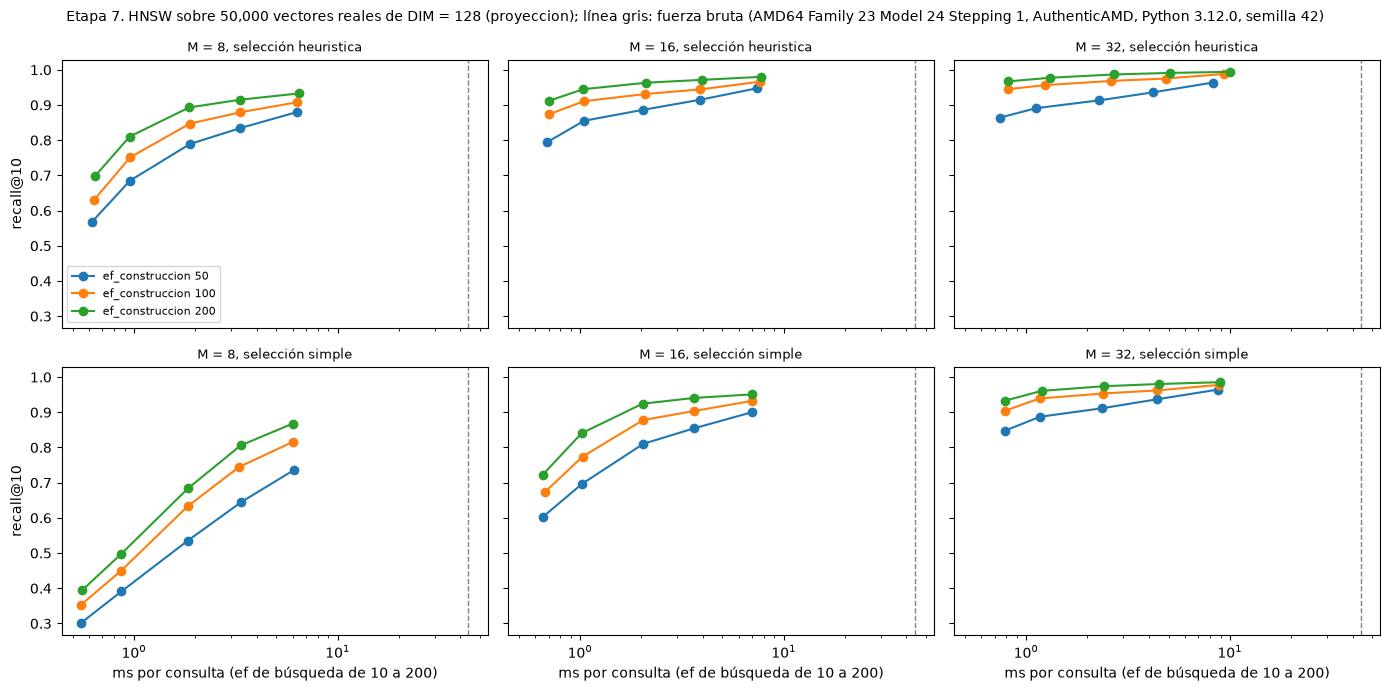

segundos_construccion  aristas  \
m  ef_construccion seleccion                                    
8  50              heuristica                  119.5   643313   
                   simple                       99.5   646493   
   100             heuristica                  224.8   658754   
                   simple                      176.2   656362   
   200             heuristica                  461.1   663645   
                   simple                      331.6   662805   
16 50              heuristica                  131.3  1123753   
                   simple                      113.6  1270305   
   100             heuristica                  257.8  1246462   
                   simple                      198.8  1282074   
   200             heuristica                  504.4  1273862   
                   simple                      374.4  1290959   
32 50              heuristica                  132.2  1514854   
                   simple                      150.3  2532778   
   100             heuristica                  293.5  2190557   
                   simple                      257.0  2551157   
   200             heuristica                  583.0  2394079   
                   simple                      467.8  2565562   

                               memoria_indice_bytes  
m  ef_construccion seleccion                         
8  50              heuristica              28173252  
                   simple                  28185972  
   100             heuristica              28235016  
                   simple                  28225448  
   200             heuristica              28254580  
                   simple                  28251220  
16 50              heuristica              30095012  
                   simple                  30681220  
   100             heuristica              30585848  
                   simple                  30728296  
   200             heuristica              30695448  
                   simple                  30763836  
32 50              heuristica              31659416  
                   simple                  35731112  
   100             heuristica              34362228  
                   simple                  35804628  
   200             heuristica              35176316  
                   simple                  35862248

ef_busqueda                      10     20     50     100    200
m  ef_construccion seleccion                                    
8  50              heuristica  0.568  0.685  0.789  0.834  0.880
                   simple      0.302  0.391  0.535  0.645  0.736
   100             heuristica  0.630  0.751  0.847  0.879  0.908
                   simple      0.353  0.450  0.633  0.745  0.816
   200             heuristica  0.698  0.810  0.893  0.915  0.933
                   simple      0.395  0.498  0.684  0.806  0.868
16 50              heuristica  0.794  0.855  0.886  0.915  0.947
                   simple      0.602  0.697  0.810  0.855  0.900
   100             heuristica  0.873  0.911  0.931  0.944  0.966
                   simple      0.674  0.774  0.878  0.904  0.932
   200             heuristica  0.912  0.945  0.963  0.972  0.980
                   simple      0.722  0.841  0.924  0.941  0.951
32 50              heuristica  0.864  0.891  0.913  0.936  0.964
                   simple      0.848  0.887  0.911  0.937  0.965
   100             heuristica  0.945  0.956  0.968  0.975  0.988
                   simple      0.905  0.939  0.953  0.962  0.978
   200             heuristica  0.967  0.978  0.987  0.991  0.994
                   simple      0.933  0.961  0.974  0.980  0.986

In [11]:
N_GRILLA_HNSW = 50_000
GRILLA_M = [8, 16, 32]
GRILLA_EF_CONSTRUCCION = [50, 100, 200]
GRILLA_SELECCION = ["heuristica", "simple"]
GRILLA_EF_BUSQUEDA = [10, 20, 50, 100, 200]


def experimento_grilla_hnsw():
    rng = np.random.default_rng(SEED)
    X = V[rng.choice(len(V), size=min(N_GRILLA_HNSW, len(V)), replace=False)]
    consultas = rng.choice(len(X), size=N_CONSULTAS, replace=False).tolist()
    referencia = [similares_exactos(X, i, K) for i in consultas]
    filas = []
    for m, ef_construccion, seleccion in product(GRILLA_M, GRILLA_EF_CONSTRUCCION, GRILLA_SELECCION):
        segundos, indice = medir(lambda: HNSW(X.shape[1], m, ef_construccion, EF_BUSQUEDA, seleccion, SEED,
                                              capacidad=len(X)).agregar_todos(X))
        for ef in GRILLA_EF_BUSQUEDA:
            recall, distancias, t_consulta = [], 0, 0.0
            for i, exacto in zip(consultas, referencia):
                t0 = time.perf_counter()
                aproximado = similares_hnsw(indice, X, i, K, ef)
                t_consulta += time.perf_counter() - t0
                distancias += indice.distancias_calculadas
                recall.append(recall_at_k(aproximado, exacto))
            filas.append({"dim": X.shape[1], "n": len(X), "m": m, "ef_construccion": ef_construccion,
                          "seleccion": seleccion, "ef_busqueda": ef, "consultas": len(consultas),
                          "segundos_construccion": segundos, "aristas": indice.n_aristas(),
                          "memoria_indice_bytes": indice.memoria_bytes, "recall_at_k": float(np.nanmean(recall)),
                          "distancias_por_consulta": distancias / len(consultas),
                          "ms_consulta_hnsw": t_consulta / len(consultas) * 1e3})
        print(f"M = {m}, ef_construccion = {ef_construccion}, {seleccion}: construcción {segundos:.0f} s", flush=True)
        del indice
    return pd.DataFrame(filas)


grilla_hnsw = resultados(R / f"grilla_hnsw_dim{DIM}_{REDUCCION}.csv", experimento_grilla_hnsw)
n_grilla = int(grilla_hnsw["n"].iloc[0])
t0 = time.perf_counter()
X_grilla = V[np.random.default_rng(SEED).choice(len(V), size=n_grilla, replace=False)]
for i in range(100):
    similares_exactos(X_grilla, i, K)
ms_bruta_grilla = (time.perf_counter() - t0) / 100 * 1e3
print(f"Fuerza bruta sobre {n_grilla:,} vectores: {ms_bruta_grilla:.1f} ms por consulta")

fig, axes = plt.subplots(len(GRILLA_SELECCION), len(GRILLA_M), figsize=(14, 7), sharex=True, sharey=True)
for (fila, seleccion), (columna, m) in product(enumerate(GRILLA_SELECCION), enumerate(GRILLA_M)):
    ax = axes[fila, columna]
    for ef_construccion, d in grilla_hnsw[(grilla_hnsw["seleccion"] == seleccion) & (grilla_hnsw["m"] == m)].groupby("ef_construccion"):
        ax.plot(d["ms_consulta_hnsw"], d["recall_at_k"], marker="o", label=f"ef_construccion {ef_construccion}")
    ax.axvline(ms_bruta_grilla, color="gray", ls="--", lw=1)
    ax.set_xscale("log"); ax.set_title(f"M = {m}, selección {seleccion}", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("ms por consulta (ef de búsqueda de 10 a 200)")
for ax in axes[:, 0]:
    ax.set_ylabel(f"recall@{K}")
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"Etapa 7. HNSW sobre {n_grilla:,} vectores reales de DIM = {DIM} ({REDUCCION}); línea gris: fuerza bruta "
             f"({plataforma_de(grilla_hnsw)}, semilla {SEED})", fontsize=10)
fig.tight_layout(); fig.savefig(R / f"grilla_hnsw_dim{DIM}_{REDUCCION}.png", dpi=150); plt.show()

construccion = grilla_hnsw.groupby(["m", "ef_construccion", "seleccion"])[["segundos_construccion", "aristas",
                                                                             "memoria_indice_bytes"]].first()
display(construccion.round(1))
grilla_hnsw.pivot_table(index=["m", "ef_construccion", "seleccion"], columns="ef_busqueda",
                        values="recall_at_k").round(3)

**Elección de los parámetros de HNSW.** La grilla completa tardó unos 81 minutos, casi todo en las 18 construcciones (de 100 a 583 s cada una sobre 50 000 vectores). La fuerza bruta tarda 43.8 ms por consulta.

- **Selección de vecinos: `SELECCION = "heuristica"`.** Con los mismos M, `ef_construccion` y `ef`, la heurística tiene más recall@K que la selección simple en casi todas las combinaciones, y la diferencia es mayor cuanto menor es M. Con `ef_construccion` = 100 y `ef` = 50, la heurística llega a 0.847 frente a 0.633 con M = 8, a 0.931 frente a 0.878 con M = 16 y a 0.968 frente a 0.953 con M = 32. Con pocas aristas por nodo, la selección simple conecta cada punto con vecinos de su misma zona densa y el grafo pierde las aristas hacia otras regiones, que la heurística conserva (Malkov y Yashunin, 2020). El tiempo por consulta es casi igual con las dos, y la heurística cuesta algo más al construir, porque compara cada candidato con los vecinos ya aceptados.
- **Vecinos por nodo: `M = 32`.** Con `ef_construccion` = 100 y `ef` = 50, el recall@K pasa de 0.847 con M = 8 a 0.931 con M = 16 y 0.968 con M = 32, con 1.9, 2.1 y 2.6 ms por consulta. Para llegar a 0.966 con M = 16 hace falta `ef` = 200 y 7.7 ms por consulta. La construcción con M = 32 cuesta 294 s frente a 258 s con M = 16, y el índice ocupa 34.4 MB frente a 30.6 MB, de los que 25.6 MB son los vectores.
- **Candidatos al insertar: `EF_CONSTRUCCION = 100`.** Con M = 32 y `ef` = 50, subir a 200 lleva el recall@K de 0.968 a 0.987, pero duplica la construcción (583 frente a 294 s). Esa diferencia se paga en la construcción con los 195 mil productos del paso 7 y, sobre todo, en la construcción con 1M del paso 9, que pasaría de unas dos horas a unas cuatro. Bajar a 50 ahorra la mitad de la construcción pero deja el recall en 0.913.
- **Candidatos al consultar: `EF_BUSQUEDA = 50`.** Con el índice elegido, `ef` = 20 da recall@K 0.956 con 1.24 ms y `ef` = 50 da 0.968 con 2.60 ms, 17 veces menos que la fuerza bruta. Se elige 50 para tener margen, porque con los 195 mil productos del paso 7 el recall baja respecto de esta muestra de 50 mil. Como `ef` solo afecta a la consulta, se puede ajustar sin reconstruir el índice si el paso 7 lo pide.

## Paso 7. Resultados en el pipeline

`ejecutar_etapa` aplica las dos familias a todos los productos con los parámetros de `src/etapa_7/similarity.py`.

1. **Conjuntos.** Quita a los usuarios bloqueados por la etapa 6, conserva los productos con al menos `MIN_USUARIOS` usuarios, calcula sus firmas y su índice LSH, y escribe los K productos relacionados de cada uno con su Jaccard exacta.
2. **Vectores.** Construye los vectores de todos los productos de la matriz y el índice HNSW, y escribe los K productos similares de cada uno con su distancia.
3. **Evaluación.** En una muestra de `N_CONSULTAS` productos compara cada respuesta con su línea base exacta por fuerza bruta y mide el recall@K y el tiempo por consulta. El producto consultado se excluye de las dos respuestas.

La celda siguiente la ejecuta. La construcción de HNSW con todos los productos en Python tarda varios minutos; la función imprime el avance cada 50 000 productos.

In [ ]:
from src.etapa_7.similarity import ejecutar_etapa

t0 = time.perf_counter()
metricas = ejecutar_etapa()
print(f"Etapa 7 sobre todos los productos: {time.perf_counter() - t0:.0f} s")

In [ ]:
metricas = json.loads(RUTA_METRICAS.read_text(encoding="utf-8"))
c, v = metricas["conjuntos"], metricas["vectores"]
resumen = pd.DataFrame({
    "MinHash + LSH": {"productos": c["productos"], "parámetros": f"mín. {c['min_usuarios']} usuarios, {c['n_hashes']} funciones, "
                                                                f"{c['bandas']} × {c['filas']}",
                      "construcción (s)": c["segundos_firmas"] + c["segundos_indice"],
                      "memoria de la estructura (MB)": (c["memoria_firmas_bytes"] + c["memoria_lsh_bytes"]) / 1e6,
                      f"recall@{metricas['k']}": c["recall_at_k"], "ms por consulta": c["ms_por_consulta_lsh"],
                      "ms por consulta, fuerza bruta": c["ms_por_consulta_fuerza_bruta"],
                      "evaluadas por consulta": f"{c['candidatos_por_consulta']:.0f} candidatos"},
    "HNSW": {"productos": v["productos"], "parámetros": f"DIM {v['dim']} ({v['reduccion']}), M {v['m']}, "
                                                        f"ef_construccion {v['ef_construccion']}, "
                                                        f"ef {v['ef_busqueda']}, {v['seleccion']}",
             "construcción (s)": v["segundos_construccion"], "memoria de la estructura (MB)": v["memoria_hnsw_bytes"] / 1e6,
             f"recall@{metricas['k']}": v["recall_at_k"], "ms por consulta": v["ms_por_consulta_hnsw"],
             "ms por consulta, fuerza bruta": v["ms_por_consulta_fuerza_bruta"],
             "evaluadas por consulta": f"{v['distancias_por_consulta']:.0f} distancias"}})
print(f"Usuarios bloqueados excluidos: {c['usuarios_bloqueados_excluidos']}, interacciones quitadas: "
      f"{c['interacciones_excluidas']:,}; productos con al menos un relacionado: {c['productos_con_relacionados']:,}")
print(f"HNSW: nodos por capa {v['nodos_por_capa']}, {v['aristas']:,} aristas")
resumen

### Ejemplos

Para tres productos que tienen respuesta en las dos familias se muestran sus productos relacionados por comportamiento (MinHash + LSH) y similares por atributos (HNSW). Las dos listas responden preguntas distintas: la primera junta productos que los mismos usuarios miran o compran, que pueden ser complementarios, y la segunda junta productos con títulos, categoría y tienda parecidos.

In [ ]:
relacionados_tabla = pd.read_parquet(RUTA_RELACIONADOS)
similares_tabla = pd.read_parquet(RUTA_SIMILARES)
en_ambas = sorted(set(relacionados_tabla["parent_asin"]) & set(similares_tabla["parent_asin"]))
ejemplos = np.random.default_rng(SEED).choice(len(en_ambas), size=3, replace=False)
tablas = []
for asin in [en_ambas[e] for e in ejemplos]:
    r = relacionados_tabla[relacionados_tabla["parent_asin"] == asin].head(5)
    s = similares_tabla[similares_tabla["parent_asin"] == asin].head(5)
    filas = max(len(r), len(s))
    tablas.append(pd.DataFrame({
        "producto": [titulo[asin]] + [""] * (filas - 1),
        "relacionado (Jaccard)": [f"{j:.3f} {titulo[x]}" for j, x in zip(r["jaccard"], r["vecino"])] + [""] * (filas - len(r)),
        "similar (distancia)": [f"{d:.3f} {titulo[x]}" for d, x in zip(s["distancia"], s["vecino"])] + [""] * (filas - len(s))}))
pd.concat(tablas, ignore_index=True)

## Paso 8. Salida de la etapa 7

Los archivos quedan en `data/interim/<CATEGORIA>/etapa_7/`. Las columnas siguen las de `vecinos.parquet` de la etapa 5.

| Archivo | Contenido | Lo usa |
| --- | --- | --- |
| `relacionados.parquet` | `parent_asin`, `rango`, `vecino` y `jaccard`: los K productos de mayor Jaccard exacta entre los candidatos de LSH | Etapa 9 (recomendaciones por comportamiento, uso previsto) |
| `similares.parquet` | `parent_asin`, `rango`, `vecino` y `distancia`: los K productos más cercanos según HNSW | Etapa 9 (productos similares por atributos, uso previsto) |
| `vectores.npz` | `asins` y la matriz de vectores de norma 1 | Experimentos de este notebook |
| `metricas.json` | Parámetros, tiempos, memoria y recall@K de la ejecución | Informe |

In [ ]:
for ruta in (RUTA_RELACIONADOS, RUTA_SIMILARES, RUTA_VECTORES, RUTA_METRICAS):
    print(f"{ruta.name}: {ruta.stat().st_size / 1e6:.1f} MB")
print(f"{RUTA_RELACIONADOS.name}: {relacionados_tabla['parent_asin'].nunique():,} productos, {len(relacionados_tabla):,} filas")
print(f"{RUTA_SIMILARES.name}: {similares_tabla['parent_asin'].nunique():,} productos, {len(similares_tabla):,} filas")
display(relacionados_tabla.head())
similares_tabla.head()

## Paso 9. Experimentos de escalabilidad

### Diseño del experimento

| Experimento | Estructura | Línea base | Complejidad esperada |
| --- | --- | --- | --- |
| 9.1 Conjuntos | MinHash + LSH con los parámetros del módulo | Fuerza bruta: Jaccard con todos los conjuntos | Construcción O(nnz · n_hashes + b · n log n); consulta según los candidatos, frente a O(nnz) |
| 9.2 Vectores | HNSW con los parámetros del módulo | KNN exacto con el `KDTree` y con `knn_fuerza_bruta` de la etapa 5 | Construcción ≈ O(n log n) y consulta ≈ O(log n), frente a O(n · DIM) por consulta |
| 9.3 Referencia | MinHash + LSH y HNSW propios | `datasketch` 1.6.5 | Las mismas complejidades; se compara la implementación |

**Datos.** Como en la etapa 5, para alcanzar cada tamaño se remuestrean los datos reales. Un conjunto sintético es el de un producto real elegido al azar, con cada usuario reemplazado por uno al azar con probabilidad `RUIDO_CONJUNTOS`. Un vector sintético es un vector real elegido al azar más un ruido normal de desviación `RUIDO_VECTORES` en cada coordenada, normalizado otra vez a norma 1. Los datos sintéticos conservan la distribución de los tamaños de los conjuntos y de los vectores reales. Con 1M elementos, cada producto real aparece unas veces repetido con ruido, así que sus copias son sus vecinos más similares y el recall@K a esa escala es más fácil que en los datos reales. **La calidad se juzga con los datos reales de los pasos 6 y 7; este paso mide sobre todo tiempo y memoria.**

**Tamaños.** 1K, 10K, 100K y 1M. **10M no se mide.** La construcción de HNSW en Python tarda varios milisegundos por inserción, así que una construcción de 10M tomaría del orden de un día, y las firmas y el índice LSH de 10M conjuntos ocuparían decenas de GB. Para 10M se extrapolan el tiempo y la memoria con la pendiente log-log de 10K a 1M, y la celda imprime esos valores.

**Repeticiones.**

- **Consultas.** Cada repetición mide un bloque fijo de consultas, con 100 repeticiones en todos los tamaños. Las estructuras aproximadas usan bloques de `BLOQUE` consultas. Las líneas base exactas cuestan O(n) por consulta y usan bloques de min(`BLOQUE`, 1M / n) consultas, que son `BLOQUE` hasta 100K y 1 con 1M.
- **Construcción.** La primera construcción fija cuántas repeticiones caben en `PRESUPUESTO_S` = 120 s, el mismo presupuesto de 2 minutos por medición que la etapa 5, con un máximo de 100 y un mínimo de 1. La construcción de HNSW con 1M se hace una sola vez. La celda imprime el tiempo de una construcción y cuánto tardarían 100.
- **Recall@K.** Se mide en `N_RECALL` consultas por tamaño, frente a la fuerza bruta.

**Condiciones de medición.**

- **Reloj.** `time.perf_counter`, con el recolector de basura desactivado durante cada medición. La estructura medida se libera fuera del intervalo medido.
- **Memoria.** `tracemalloc`, en una pasada aparte sin medir tiempo, porque el rastreo hace más lenta cada asignación. Se reporta la memoria actual, que es la de la estructura, y la pico, que incluye los temporales de la construcción. La pasada de HNSW con 1M costaría otra construcción de una hora o más, así que para 1M se reporta la memoria de la estructura (vectores y aristas) y la extrapolación desde 100K.
- **Plataforma y semilla.** Las del paso 1. Los archivos de resultados llevan en el nombre los parámetros con que se midieron.

In [ ]:
TAMANOS = [1_000, 10_000, 100_000, 1_000_000]
N_EXTRAPOLADO = 10_000_000
REPETICIONES = 100            # bloques de consultas, en todos los tamaños
PRESUPUESTO_S = 120           # tiempo máximo por medición de la construcción
BLOQUE = 10                   # consultas por bloque
N_RECALL = 200                # consultas con que se mide el recall@K en cada tamaño
N_MAX_TRACEMALLOC_HNSW = 100_000
RUIDO_CONJUNTOS = 0.05        # probabilidad de reemplazar cada usuario de un conjunto remuestreado
RUIDO_VECTORES = 0.05         # desviación del ruido de cada coordenada de un vector remuestreado


def repeticiones_construccion(segundos):
    """Repeticiones de la construcción que caben en PRESUPUESTO_S, entre 1 y REPETICIONES."""
    return max(1, min(REPETICIONES, int(PRESUPUESTO_S // max(segundos, 1e-9))))


def bloque_exacto(n):
    """Consultas por bloque de las líneas base exactas: BLOQUE hasta 100K y 1 con 1M."""
    return max(1, min(BLOQUE, 1_000_000 // n))


def medir_construccion(construir):
    """(estructura, tiempos): la primera construcción fija cuántas repeticiones caben en el presupuesto."""
    segundos, estructura = medir(construir)
    tiempos = [segundos]
    while len(tiempos) < repeticiones_construccion(tiempos[0]):
        del estructura
        segundos, estructura = medir(construir)
        tiempos.append(segundos)
    return estructura, tiempos


def medir_consultas(funcion, consultas, bloque):
    """Milisegundos por consulta de funcion(i) en REPETICIONES bloques de `bloque` consultas, en orden circular."""
    tiempos = []
    for r in range(REPETICIONES):
        ids = [consultas[(r * bloque + j) % len(consultas)] for j in range(bloque)]
        gc.disable()
        try:
            t0 = time.perf_counter()
            for i in ids:
                funcion(i)
            tiempos.append((time.perf_counter() - t0) / bloque * 1e3)
        finally:
            gc.enable()
    return tiempos


def estadisticos(prefijo, tiempos):
    """Promedio, desviación estándar y repeticiones de una lista de tiempos."""
    return {f"{prefijo}": statistics.mean(tiempos), f"{prefijo}_std": statistics.stdev(tiempos) if len(tiempos) > 1 else 0.0,
            f"{prefijo}_repeticiones": len(tiempos)}


def remuestrear_conjuntos(base, n, semilla, ruido=RUIDO_CONJUNTOS):
    """n conjuntos: el de un producto real al azar, con cada usuario reemplazado por uno al azar con probabilidad ruido."""
    rng = np.random.default_rng(semilla)
    origen = rng.integers(0, len(base), n)
    largos = base.tam[origen]
    inicios = np.cumsum(largos) - largos
    pos = np.arange(largos.sum()) - np.repeat(inicios, largos) + np.repeat(base.indptr[origen], largos)
    indices = base.indices[pos].astype(np.int64)
    cambiar = rng.random(len(indices)) < ruido
    indices[cambiar] = rng.integers(0, base.n_usuarios, int(cambiar.sum()))
    fila = np.repeat(np.arange(n), largos)
    orden = np.lexsort((indices, fila))                   # usuarios ordenados dentro de cada conjunto
    fila, indices = fila[orden], indices[orden]
    distinto = np.r_[True, (fila[1:] != fila[:-1]) | (indices[1:] != indices[:-1])]
    fila, indices = fila[distinto], indices[distinto]     # sin usuarios repetidos dentro de un conjunto
    indptr = np.concatenate(([0], np.cumsum(np.bincount(fila, minlength=n))))
    return ConjuntosProductos([f"s{i}" for i in range(n)], indptr, indices, base.n_usuarios)


def remuestrear_vectores(base, n, semilla, ruido=RUIDO_VECTORES):
    """n vectores: uno real al azar más ruido normal en cada coordenada, normalizado a norma 1."""
    rng = np.random.default_rng(semilla)
    X = base[rng.integers(0, len(base), n)] + rng.normal(scale=ruido, size=(n, base.shape[1])).astype(np.float32)
    return (X / np.linalg.norm(X, axis=1, keepdims=True)).astype(np.float32)


def extrapolar(tabla, columna, desde=10_000, hasta=N_EXTRAPOLADO):
    """(pendiente log-log de columna frente a n desde `desde`, valor extrapolado a `hasta`)."""
    datos = tabla[(tabla["n"] >= desde) & tabla[columna].notna()]
    pendiente, ordenada = np.polyfit(np.log10(datos["n"]), np.log10(datos[columna]), 1)
    return pendiente, 10 ** (ordenada + pendiente * np.log10(hasta))


def ejes_loglog(ax, titulo, ylabel):
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(titulo, fontsize=10); ax.set_xlabel("n"); ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)

### 9.1 MinHash + LSH frente a la fuerza bruta

La construcción mide las firmas y el índice juntos, porque la estructura aproximada necesita las dos cosas. La memoria de la fuerza bruta es la de los propios conjuntos en CSR, que también usa LSH para verificar los candidatos; la de MinHash + LSH es la que agrega: las firmas y el índice. También se mide el pico de una consulta de cada método.

In [ ]:
def experimento_escala_conjuntos():
    filas = []
    for n in TAMANOS:
        t_inicio = time.perf_counter()
        datos = remuestrear_conjuntos(con_exclusion, n, SEED + n)

        def construir():
            f = MinHash(N_HASHES, SEED).firmas(datos.indptr, datos.indices)
            return f, LSH(f, BANDAS, FILAS)

        (f, indice), t_construccion = medir_construccion(construir)
        consultas = np.random.default_rng(SEED).choice(n, size=min(N_RECALL, n), replace=False).tolist()
        t_lsh = medir_consultas(lambda i: relacionados_lsh(datos, indice, i, K), consultas, BLOQUE)
        t_bruta = medir_consultas(lambda i: datos.fuerza_bruta(i, K), consultas, bloque_exacto(n))
        recall, candidatos = [], 0
        for i in consultas:
            recall.append(recall_at_k(relacionados_lsh(datos, indice, i, K), datos.fuerza_bruta(i, K)))
            candidatos += indice.candidatos_evaluados
        _, _, pico_consulta_lsh = medir_memoria(relacionados_lsh, datos, indice, consultas[0], K)
        _, _, pico_consulta_bruta = medir_memoria(datos.fuerza_bruta, consultas[0], K)
        memoria_firmas, memoria_indice = f.nbytes, indice.memoria_bytes
        del f, indice
        _, actual, pico = medir_memoria(construir)
        filas.append({"n": n, "nnz": datos.nnz, "segundos_primera": t_construccion[0],
                      **estadisticos("construccion_s", t_construccion),
                      **estadisticos("consulta_lsh_ms", t_lsh), **estadisticos("consulta_bruta_ms", t_bruta),
                      "bloque_lsh": BLOQUE, "bloque_bruta": bloque_exacto(n),
                      "recall_at_k": float(np.nanmean(recall)), "consultas_sin_vecinos": int(np.isnan(recall).sum()),
                      "candidatos_por_consulta": candidatos / len(consultas),
                      "memoria_actual_bytes": actual, "memoria_pico_bytes": pico,
                      "memoria_firmas_bytes": memoria_firmas, "memoria_indice_bytes": memoria_indice,
                      "memoria_datos_bytes": datos.indptr.nbytes + datos.indices.nbytes,
                      "pico_consulta_lsh_bytes": pico_consulta_lsh, "pico_consulta_bruta_bytes": pico_consulta_bruta})
        print(f"Conjuntos, n = {n:,}: {len(t_construccion)} construcciones de {t_construccion[0]:.1f} s "
              f"(100 tardarían {100 * t_construccion[0] / 60:.0f} min); total {time.perf_counter() - t_inicio:.0f} s",
              flush=True)
        del datos
    return pd.DataFrame(filas)


escala_conjuntos = resultados(R / f"escala_conjuntos_min{MIN_USUARIOS}_h{N_HASHES}_{BANDAS}x{FILAS}.csv",
                              experimento_escala_conjuntos)
t = escala_conjuntos
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].errorbar(t["n"], t["construccion_s"], yerr=t["construccion_s_std"], marker="o", capsize=3, label="firmas + índice LSH")
axes[1].errorbar(t["n"], t["consulta_lsh_ms"], yerr=t["consulta_lsh_ms_std"], marker="o", capsize=3, label="MinHash + LSH")
axes[1].errorbar(t["n"], t["consulta_bruta_ms"], yerr=t["consulta_bruta_ms_std"], marker="s", capsize=3, label="fuerza bruta")
axes[2].plot(t["n"], t["memoria_actual_bytes"], marker="o", label="MinHash + LSH, actual")
axes[2].plot(t["n"], t["memoria_pico_bytes"], marker="o", ls="--", label="MinHash + LSH, pico")
axes[2].plot(t["n"], t["memoria_datos_bytes"], marker="s", label="conjuntos en CSR (fuerza bruta)")
axes[2].plot(t["n"], t["pico_consulta_bruta_bytes"], marker="s", ls="--", label="pico de una consulta de fuerza bruta")
for ax, x0, y0 in [(axes[0], t["n"].iloc[0], t["construccion_s"].iloc[0]), (axes[2], t["n"].iloc[0], t["memoria_actual_bytes"].iloc[0])]:
    ax.plot(t["n"], y0 * t["n"] / x0, "k:", lw=1, label="referencia O(n)")
axes[1].plot(t["n"], t["consulta_bruta_ms"].iloc[0] * t["n"] / t["n"].iloc[0], "k:", lw=1, label="referencia O(n)")
ejes_loglog(axes[0], "Construcción", "segundos")
ejes_loglog(axes[1], "Consulta", "ms por consulta")
ejes_loglog(axes[2], "Memoria (tracemalloc)", "bytes")
fig.suptitle(f"Etapa 7. MinHash + LSH frente a fuerza bruta ({plataforma_de(t)}, semilla {SEED})", fontsize=10)
fig.tight_layout(); fig.savefig(R / "escala_conjuntos.png", dpi=150); plt.show()

filas = []
for columna in ["construccion_s", "consulta_lsh_ms", "consulta_bruta_ms", "memoria_actual_bytes", "memoria_pico_bytes"]:
    pendiente, valor = extrapolar(t, columna)
    filas.append({"medida": columna, "pendiente_log_log_desde_10K": round(pendiente, 2), "extrapolado_a_10M": valor})
display(pd.DataFrame(filas))
t[["n", "nnz", "construccion_s", "construccion_s_std", "construccion_s_repeticiones", "consulta_lsh_ms",
   "consulta_lsh_ms_std", "consulta_bruta_ms", "consulta_bruta_ms_std", "consulta_lsh_ms_repeticiones",
   "recall_at_k", "candidatos_por_consulta", "memoria_actual_bytes", "memoria_pico_bytes"]].round(4)

### 9.2 HNSW frente al KNN exacto

Para cada tamaño se construyen el HNSW y el `KDTree` de la etapa 5 sobre los mismos vectores, y se miden las consultas de los dos y de la fuerza bruta. El KD-Tree se pide con K + 1 vecinos, porque la consulta es un punto del conjunto. Se registra también la fracción de puntos que evalúa el KD-Tree, que según el experimento B de la etapa 5 debería ser cercana a 1 con d = DIM. La construcción de HNSW con 1M tarda del orden de una a dos horas.

In [ ]:
def experimento_escala_hnsw():
    filas = []
    for n in TAMANOS:
        t_inicio = time.perf_counter()
        X = remuestrear_vectores(V, n, SEED + n)

        def construir():
            return HNSW(X.shape[1], M, EF_CONSTRUCCION, EF_BUSQUEDA, SELECCION, SEED, capacidad=n).agregar_todos(X)

        indice, t_construccion = medir_construccion(construir)
        arbol, t_kd = medir_construccion(lambda: KDTree(X))
        consultas = np.random.default_rng(SEED).choice(n, size=min(N_RECALL, n), replace=False).tolist()
        t_hnsw = medir_consultas(lambda i: similares_hnsw(indice, X, i, K), consultas, BLOQUE)
        t_arbol = medir_consultas(lambda i: arbol.knn(X[i], K + 1), consultas, bloque_exacto(n))
        t_bruta = medir_consultas(lambda i: similares_exactos(X, i, K), consultas, bloque_exacto(n))
        recall, distancias, evaluados = [], 0, 0
        for i in consultas:
            recall.append(recall_at_k(similares_hnsw(indice, X, i, K), similares_exactos(X, i, K)))
            distancias += indice.distancias_calculadas
        for i in consultas[:bloque_exacto(n) * 2]:
            arbol.knn(X[i], K + 1)
            evaluados += arbol.puntos_evaluados / n
        _, _, pico_consulta_hnsw = medir_memoria(similares_hnsw, indice, X, consultas[0], K)
        _, _, pico_consulta_bruta = medir_memoria(similares_exactos, X, consultas[0], K)
        memoria_estructura = indice.memoria_bytes
        del indice, arbol
        actual = pico = np.nan
        if n <= N_MAX_TRACEMALLOC_HNSW:
            _, actual, pico = medir_memoria(construir)
        _, actual_kd, pico_kd = medir_memoria(KDTree, X)
        filas.append({"n": n, "segundos_primera": t_construccion[0], **estadisticos("construccion_s", t_construccion),
                      "segundos_primera_kd": t_kd[0], **estadisticos("construccion_kd_s", t_kd),
                      **estadisticos("consulta_hnsw_ms", t_hnsw), **estadisticos("consulta_kd_ms", t_arbol),
                      **estadisticos("consulta_bruta_ms", t_bruta), "bloque_hnsw": BLOQUE, "bloque_exacto": bloque_exacto(n),
                      "recall_at_k": float(np.nanmean(recall)), "distancias_por_consulta": distancias / len(consultas),
                      "fraccion_evaluada_kd": evaluados / len(consultas[:bloque_exacto(n) * 2]),
                      "memoria_actual_bytes": actual, "memoria_pico_bytes": pico, "memoria_estructura_bytes": memoria_estructura,
                      "memoria_actual_kd_bytes": actual_kd, "memoria_pico_kd_bytes": pico_kd,
                      "memoria_vectores_bytes": X.nbytes, "pico_consulta_hnsw_bytes": pico_consulta_hnsw,
                      "pico_consulta_bruta_bytes": pico_consulta_bruta})
        print(f"HNSW, n = {n:,}: {len(t_construccion)} construcciones de {t_construccion[0]:.1f} s "
              f"(100 tardarían {100 * t_construccion[0] / 3600:.1f} h); total {time.perf_counter() - t_inicio:.0f} s",
              flush=True)
        del X
    return pd.DataFrame(filas)


escala_hnsw = resultados(R / f"escala_hnsw_d{DIM}_{REDUCCION}_m{M}_efc{EF_CONSTRUCCION}_ef{EF_BUSQUEDA}_{SELECCION}.csv",
                         experimento_escala_hnsw)

In [ ]:
t = escala_hnsw
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].errorbar(t["n"], t["construccion_s"], yerr=t["construccion_s_std"], marker="o", capsize=3, label="HNSW")
axes[0].errorbar(t["n"], t["construccion_kd_s"], yerr=t["construccion_kd_s_std"], marker="^", capsize=3, label="KD-Tree")
axes[0].plot(t["n"], t["construccion_s"].iloc[0] * (t["n"] * np.log(t["n"])) / (t["n"].iloc[0] * np.log(t["n"].iloc[0])),
             "k:", lw=1, label="referencia O(n log n)")
axes[1].errorbar(t["n"], t["consulta_hnsw_ms"], yerr=t["consulta_hnsw_ms_std"], marker="o", capsize=3, label="HNSW")
axes[1].errorbar(t["n"], t["consulta_kd_ms"], yerr=t["consulta_kd_ms_std"], marker="^", capsize=3, label="KD-Tree (exacto)")
axes[1].errorbar(t["n"], t["consulta_bruta_ms"], yerr=t["consulta_bruta_ms_std"], marker="s", capsize=3, label="fuerza bruta")
axes[1].plot(t["n"], t["consulta_bruta_ms"].iloc[0] * t["n"] / t["n"].iloc[0], "k:", lw=1, label="referencia O(n)")
axes[1].plot(t["n"], t["consulta_hnsw_ms"].iloc[0] * np.log(t["n"]) / np.log(t["n"].iloc[0]), "k--", lw=1,
             label="referencia O(log n)")
axes[2].plot(t["n"], t["memoria_actual_bytes"], marker="o", label="HNSW, actual")
axes[2].plot(t["n"], t["memoria_pico_bytes"], marker="o", ls="--", label="HNSW, pico")
axes[2].plot(t["n"], t["memoria_estructura_bytes"], marker="x", ls=":", label="HNSW, vectores + aristas")
axes[2].plot(t["n"], t["memoria_actual_kd_bytes"], marker="^", label="KD-Tree, actual")
axes[2].plot(t["n"], t["memoria_vectores_bytes"], marker="s", label="vectores (fuerza bruta)")
axes[2].plot(t["n"], t["pico_consulta_bruta_bytes"], marker="s", ls="--", label="pico de una consulta de fuerza bruta")
ejes_loglog(axes[0], "Construcción", "segundos")
ejes_loglog(axes[1], "Consulta", "ms por consulta")
ejes_loglog(axes[2], "Memoria (tracemalloc)", "bytes")
fig.suptitle(f"Etapa 7. HNSW frente a KNN exacto, DIM = {DIM} ({plataforma_de(t)}, semilla {SEED})", fontsize=10)
fig.tight_layout(); fig.savefig(R / "escala_hnsw.png", dpi=150); plt.show()

filas = []
for columna in ["construccion_s", "consulta_hnsw_ms", "consulta_kd_ms", "consulta_bruta_ms", "memoria_actual_bytes",
                "memoria_estructura_bytes"]:
    pendiente, valor = extrapolar(t, columna)
    filas.append({"medida": columna, "pendiente_log_log_desde_10K": round(pendiente, 2), "extrapolado_a_10M": valor})
extrapolacion_hnsw = pd.DataFrame(filas)
display(extrapolacion_hnsw)
horas_10m = extrapolacion_hnsw.loc[extrapolacion_hnsw["medida"] == "construccion_s", "extrapolado_a_10M"].iloc[0] / 3600
print(f"Construcción de HNSW con 10M extrapolada: {horas_10m:.1f} h")
t[["n", "construccion_s", "construccion_s_std", "construccion_s_repeticiones", "consulta_hnsw_ms", "consulta_hnsw_ms_std",
   "consulta_kd_ms", "consulta_bruta_ms", "consulta_hnsw_ms_repeticiones", "recall_at_k", "distancias_por_consulta",
   "fraccion_evaluada_kd", "memoria_actual_bytes", "memoria_pico_bytes", "memoria_estructura_bytes"]].round(4)

### 9.3 Comparación con una implementación de referencia

La rúbrica pide comparar con implementaciones de referencia. Se usa `datasketch` (versión 1.6.5), una biblioteca en Python, para que la comparación sea en el mismo lenguaje, como `pyprobables` en la etapa 6.

- **MinHash + LSH.** `datasketch.MinHash` con `N_HASHES` funciones calcula la firma de cada conjunto a partir de un SHA-1 de cada usuario. `MinHashLSH` recibe la misma partición `(BANDAS, FILAS)` y guarda las cubetas en diccionarios. Los candidatos se verifican con la misma Jaccard exacta que la versión propia.
- **HNSW.** `datasketch.hnsw.HNSW` con los mismos M y `ef_construccion`, y la misma distancia euclidiana; se consulta con el mismo `ef`.

Las dos implementaciones reciben los mismos datos remuestreados de 9.1 y 9.2, con las mismas semillas, y las mediciones propias son las de esas tablas. La comparación llega hasta 100K con el mismo protocolo de repeticiones; la celda imprime el tiempo de una construcción de cada tamaño.

In [ ]:
from datasketch import MinHash as MinHashRef, MinHashLSH
from datasketch.hnsw import HNSW as HNSWRef

TAMANOS_REF = [1_000, 10_000, 100_000]


def construir_lsh_ref(datos):
    indice = MinHashLSH(num_perm=N_HASHES, params=(BANDAS, FILAS))
    firmas_ref = []
    with indice.insertion_session() as sesion:
        for i in range(len(datos)):
            firma = MinHashRef(num_perm=N_HASHES, seed=SEED)
            firma.update_batch([u.to_bytes(4, "little") for u in datos.usuarios(i).tolist()])
            sesion.insert(i, firma)
            firmas_ref.append(firma)
    return indice, firmas_ref


def relacionados_ref(datos, indice, firmas_ref, i, k):
    candidatos = np.array([j for j in indice.query(firmas_ref[i]) if j != i], dtype=np.int64)
    return k_mejores(datos.jaccard(i, candidatos), candidatos, k)


def distancia(a, b):
    d = a - b
    return float(np.sqrt(np.dot(d, d)))


def construir_hnsw_ref(X):
    indice = HNSWRef(distance_func=distancia, m=M, ef_construction=EF_CONSTRUCCION, seed=SEED)
    for i, x in enumerate(X):
        indice.insert(i, x)
    return indice


def similares_ref(indice, X, i, k):
    return [(d, j) for j, d in indice.query(X[i], k=k + 1, ef=max(EF_BUSQUEDA, k + 1)) if j != i][:k]


def experimento_referencia():
    filas = []
    for n in TAMANOS_REF:
        datos = remuestrear_conjuntos(con_exclusion, n, SEED + n)
        consultas = np.random.default_rng(SEED).choice(n, size=min(N_RECALL, n), replace=False).tolist()
        (indice, firmas_ref), t_construccion = medir_construccion(lambda: construir_lsh_ref(datos))
        t_consulta = medir_consultas(lambda i: relacionados_ref(datos, indice, firmas_ref, i, K), consultas, BLOQUE)
        recall = np.nanmean([recall_at_k(relacionados_ref(datos, indice, firmas_ref, i, K), datos.fuerza_bruta(i, K))
                          for i in consultas])
        del indice, firmas_ref
        _, actual, pico = medir_memoria(construir_lsh_ref, datos)
        filas.append({"familia": "MinHash + LSH", "implementacion": "datasketch", "n": n,
                      "segundos_primera": t_construccion[0], **estadisticos("construccion_s", t_construccion),
                      **estadisticos("consulta_ms", t_consulta), "recall_at_k": float(recall),
                      "memoria_actual_bytes": actual, "memoria_pico_bytes": pico})
        print(f"datasketch MinHash + LSH, n = {n:,}: construcción {t_construccion[0]:.1f} s", flush=True)
        del datos

        X = remuestrear_vectores(V, n, SEED + n)
        indice, t_construccion = medir_construccion(lambda: construir_hnsw_ref(X))
        t_consulta = medir_consultas(lambda i: similares_ref(indice, X, i, K), consultas, BLOQUE)
        recall = np.nanmean([recall_at_k(similares_ref(indice, X, i, K), similares_exactos(X, i, K)) for i in consultas])
        del indice
        _, actual, pico = medir_memoria(construir_hnsw_ref, X)
        filas.append({"familia": "HNSW", "implementacion": "datasketch", "n": n,
                      "segundos_primera": t_construccion[0], **estadisticos("construccion_s", t_construccion),
                      **estadisticos("consulta_ms", t_consulta), "recall_at_k": float(recall),
                      "memoria_actual_bytes": actual, "memoria_pico_bytes": pico})
        print(f"datasketch HNSW, n = {n:,}: construcción {t_construccion[0]:.1f} s", flush=True)
        del X
    return pd.DataFrame(filas)


referencia_ds = resultados(R / f"referencia_min{MIN_USUARIOS}_h{N_HASHES}_{BANDAS}x{FILAS}_d{DIM}_{REDUCCION}_m{M}_efc{EF_CONSTRUCCION}"
                              f"_ef{EF_BUSQUEDA}.csv", experimento_referencia)
propias = pd.concat([
    escala_conjuntos.assign(familia="MinHash + LSH", consulta_ms=escala_conjuntos["consulta_lsh_ms"],
                            consulta_ms_std=escala_conjuntos["consulta_lsh_ms_std"]),
    escala_hnsw.assign(familia="HNSW", consulta_ms=escala_hnsw["consulta_hnsw_ms"],
                       consulta_ms_std=escala_hnsw["consulta_hnsw_ms_std"])]).assign(implementacion="propia")
columnas = ["familia", "implementacion", "n", "construccion_s", "construccion_s_std", "construccion_s_repeticiones",
            "consulta_ms", "consulta_ms_std", "recall_at_k", "memoria_actual_bytes", "memoria_pico_bytes"]
comparacion = pd.concat([propias[propias["n"].isin(TAMANOS_REF)][columnas], referencia_ds[columnas]], ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for (familia, implementacion), d in comparacion.groupby(["familia", "implementacion"], sort=False):
    estilo = "-" if implementacion == "propia" else "--"
    etiqueta = f"{familia}, {implementacion}"
    axes[0].errorbar(d["n"], d["construccion_s"], yerr=d["construccion_s_std"], ls=estilo, marker="o", capsize=3, label=etiqueta)
    axes[1].errorbar(d["n"], d["consulta_ms"], yerr=d["consulta_ms_std"], ls=estilo, marker="o", capsize=3, label=etiqueta)
    axes[2].plot(d["n"], d["memoria_actual_bytes"], ls=estilo, marker="o", label=etiqueta)
ejes_loglog(axes[0], "Construcción", "segundos")
ejes_loglog(axes[1], "Consulta", "ms por consulta")
ejes_loglog(axes[2], "Memoria actual (tracemalloc)", "bytes")
fig.suptitle(f"Etapa 7. Implementaciones propias frente a datasketch ({plataforma_de(referencia_ds)}, semilla {SEED})",
             fontsize=10)
fig.tight_layout(); fig.savefig(R / "referencia.png", dpi=150); plt.show()
comparacion.set_index(["familia", "n", "implementacion"]).sort_index().round(4)

### Verificación del protocolo

La celda comprueba que cada medición de tiempo guardada tiene las repeticiones del diseño: 100 bloques en todas las consultas y, en cada construcción, las que caben en `PRESUPUESTO_S` según la duración de la primera.

In [ ]:
for nombre, tabla, consultas_cols, construcciones in [
        ("9.1", escala_conjuntos, ["consulta_lsh_ms", "consulta_bruta_ms"], [("construccion_s", "segundos_primera")]),
        ("9.2", escala_hnsw, ["consulta_hnsw_ms", "consulta_kd_ms", "consulta_bruta_ms"],
         [("construccion_s", "segundos_primera"), ("construccion_kd_s", "segundos_primera_kd")]),
        ("9.3", referencia_ds, ["consulta_ms"], [("construccion_s", "segundos_primera")])]:
    for columna in consultas_cols:
        assert (tabla[f"{columna}_repeticiones"] == REPETICIONES).all(), f"{nombre}: {columna}"
    for columna, primera in construcciones:
        esperadas = tabla[primera].map(repeticiones_construccion)
        assert (tabla[f"{columna}_repeticiones"] == esperadas).all(), f"{nombre}: {columna}"
    menos = tabla[tabla["construccion_s_repeticiones"] < REPETICIONES]
    for _, f in menos.iterrows():
        print(f"{nombre}, n = {int(f['n']):,}: {int(f['construccion_s_repeticiones'])} construcciones de {f['segundos_primera']:.1f} s; "
              f"100 tardarían {100 * f['segundos_primera'] / 60:.0f} min")
print("Las consultas tienen 100 repeticiones en todos los tamaños y las construcciones las que caben en el presupuesto.")

## Referencias

Aumüller, M., Bernhardsson, E., y Faithfull, A. (2020). ANN-Benchmarks: A benchmarking tool for approximate nearest neighbor algorithms. *Information Systems*, 87, 101374.
Broder, A. Z. (1997). On the resemblance and containment of documents. *Proceedings of the Compression and Complexity of Sequences*, 21-29. IEEE.
Broder, A. Z., Charikar, M., Frieze, A. M., y Mitzenmacher, M. (2000). Min-wise independent permutations. *Journal of Computer and System Sciences*, 60(3), 630-659.
Carter, J. L., y Wegman, M. N. (1979). Universal classes of hash functions. *Journal of Computer and System Sciences*, 18(2), 143-154.
Charikar, M. (2002). Similarity estimation techniques from rounding algorithms. *Proceedings of the 34th Annual ACM Symposium on Theory of Computing*, 380-388.
Deerwester, S., Dumais, S. T., Furnas, G. W., Landauer, T. K., y Harshman, R. (1990). Indexing by latent semantic analysis. *Journal of the American Society for Information Science*, 41(6), 391-407.
Eckart, C., y Young, G. (1936). The approximation of one matrix by another of lower rank. *Psychometrika*, 1(3), 211-218.
Halko, N., Martinsson, P.-G., y Tropp, J. A. (2011). Finding structure with randomness: Probabilistic algorithms for constructing approximate matrix decompositions. *SIAM Review*, 53(2), 217-288.
Indyk, P., y Motwani, R. (1998). Approximate nearest neighbors: Towards removing the curse of dimensionality. *Proceedings of the 30th Annual ACM Symposium on Theory of Computing*, 604-613.
Jégou, H., Douze, M., y Schmid, C. (2011). Product quantization for nearest neighbor search. *IEEE Transactions on Pattern Analysis and Machine Intelligence*, 33(1), 117-128.
Johnson, W. B., y Lindenstrauss, J. (1984). Extensions of Lipschitz mappings into a Hilbert space. *Contemporary Mathematics*, 26, 189-206.
Leskovec, J., Rajaraman, A., y Ullman, J. D. (2020). *Mining of Massive Datasets* (3.ª ed.). Cambridge University Press.
Malkov, Y. A., Ponomarenko, A., Logvinov, A., y Krylov, V. (2014). Approximate nearest neighbor algorithm based on navigable small world graphs. *Information Systems*, 45, 61-68.
Malkov, Y. A., y Yashunin, D. A. (2020). Efficient and robust approximate nearest neighbor search using hierarchical navigable small world graphs. *IEEE Transactions on Pattern Analysis and Machine Intelligence*, 42(4), 824-836.
Salton, G., y Buckley, C. (1988). Term-weighting approaches in automatic text retrieval. *Information Processing & Management*, 24(5), 513-523.
Weinberger, K., Dasgupta, A., Langford, J., Smola, A., y Attenberg, J. (2009). Feature hashing for large scale multitask learning. *Proceedings of the 26th International Conference on Machine Learning*, 1113-1120.
Zhu, E. *datasketch: Big Data Looks Small* (versión 1.6.5) [software]. https://github.com/ekzhu/datasketch